# [과제3] 특성 공학(Feature Engineering) 파이프라인 — Titanic 생존 예측

- 이름: 송종민 / 학번: ________
- GitHub: https://github.com/ps514/Bigdata
- 데이터셋: Kaggle *Titanic - Machine Learning from Disaster* (`train.csv`)
- 문제 유형: 이진 분류 (타깃 `Survived`)

| STEP | 내용 |
|---|---|
| 01 | 데이터 준비 (소개, 컬럼 설명, shape, 타깃 정의) |
| 02 | EDA (결측치, 이상치, 분포, 상관관계, 타깃 분포) |
| 03 | 특성 공학 비교 실험 (결측치 / 인코딩 / 스케일링 / 파생 변수) |
| 04 | 변수 선택 (Random Forest 중요도 상위 N개, 제거 전/후 비교) |
| 05 | 모델 학습·평가 (LogReg, RandomForest, XGBoost, LightGBM) + 실험 비교표 (Base, Exp-1~3) |
| 가산점 | Pipeline, GridSearchCV, SHAP, Feature Importance 시각화 |
| 결론 | 과제에서 요구한 5가지 질문에 답하기 |

## 0. 환경 설정

In [1]:
import os, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, MinMaxScaler, RobustScaler)
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split, GridSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
# 한글 폰트
_font = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = _font
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)

SEED = 42
np.random.seed(SEED)

## STEP 01. 데이터 준비
### 1-1. 데이터셋 소개
- 출처: Kaggle *Titanic - Machine Learning from Disaster* (https://www.kaggle.com/competitions/titanic/data)
- 1912년 타이타닉호 승객 정보로 생존 여부를 예측하는 **지도학습(이진 분류)** 데이터
- `train.csv` 891행 사용 (필수 조건: 500개 이상 ✓)
- 수치형(Age, Fare, SibSp, Parch)과 범주형(Sex, Embarked, Pclass 등)이 섞여 있고 결측치가 있어 특성 공학 실습에 적합

In [2]:
df = pd.read_csv("data/train.csv")
print("데이터 shape:", df.shape)
df.head()

데이터 shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1-2. 컬럼 설명표

In [3]:
col_desc = pd.DataFrame({
    "컬럼": ["PassengerId", "Survived", "Pclass", "Name", "Sex", "Age", "SibSp",
             "Parch", "Ticket", "Fare", "Cabin", "Embarked"],
    "설명": ["승객 ID", "생존 여부 (0=사망, 1=생존) ← 타깃", "객실 등급 (1/2/3등석)", "이름 (호칭 포함)",
             "성별", "나이", "함께 탑승한 형제·배우자 수", "함께 탑승한 부모·자녀 수",
             "티켓 번호", "운임", "객실 번호", "탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)"],
    "유형": ["식별자", "타깃(이진)", "범주형(순서)", "텍스트", "범주형", "수치형", "수치형",
             "수치형", "텍스트", "수치형", "범주형/텍스트", "범주형"],
})
col_desc["dtype"] = col_desc["컬럼"].map(df.dtypes.astype(str))
col_desc["결측 수"] = col_desc["컬럼"].map(df.isna().sum())
col_desc

,컬럼,설명,유형,dtype,결측 수
0,PassengerId,승객 ID,식별자,int64,0
1,Survived,"생존 여부 (0=사망, 1=생존) ← 타깃",타깃(이진),int64,0
2,Pclass,객실 등급 (1/2/3등석),범주형(순서),int64,0
3,Name,이름 (호칭 포함),텍스트,str,0
4,Sex,성별,범주형,str,0
5,Age,나이,수치형,float64,177
6,SibSp,함께 탑승한 형제·배우자 수,수치형,int64,0
7,Parch,함께 탑승한 부모·자녀 수,수치형,int64,0
8,Ticket,티켓 번호,텍스트,str,0
9,Fare,운임,수치형,float64,0


### 1-3. 타깃 변수 정의
- **타깃: `Survived`** (0 = 사망, 1 = 생존)
- 학습에 쓰지 않는 컬럼: `PassengerId`(식별자), `Ticket`(고유값이 많은 텍스트), `Cabin`(결측 77% → 파생 변수 `HasCabin`으로만 사용), `Name`(파생 변수 `Title`로만 사용)

In [4]:
TARGET = "Survived"
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## STEP 02. 탐색적 데이터 분석 (EDA)
### 2-1. 결측치 비율 분석

,결측 수,결측 비율(%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


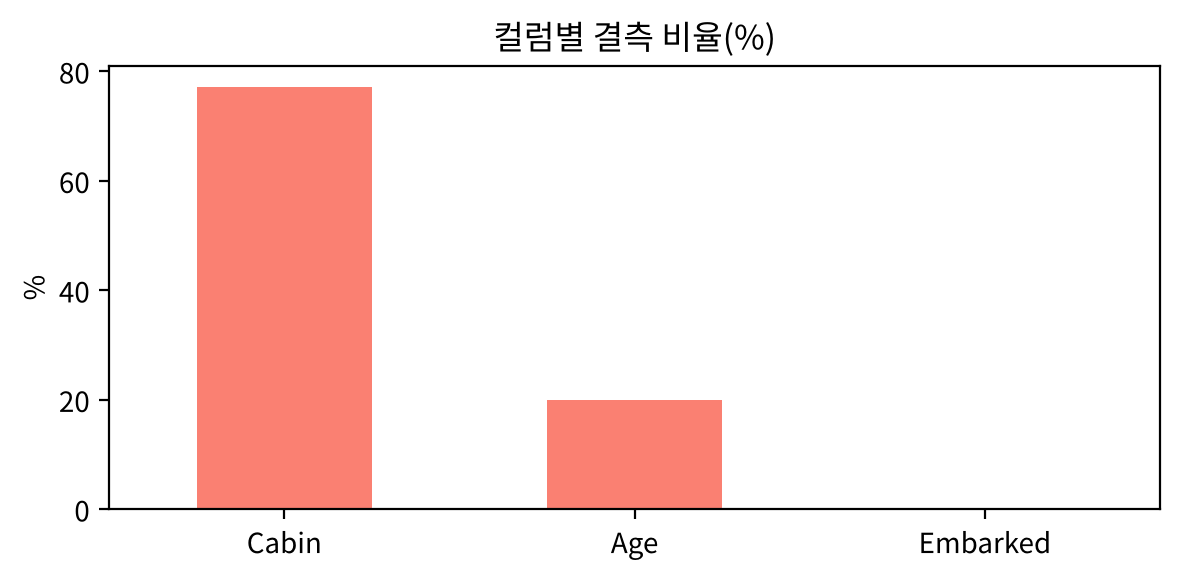

In [5]:
missing = pd.DataFrame({"결측 수": df.isna().sum(), "결측 비율(%)": (df.isna().mean() * 100).round(2)})
missing = missing[missing["결측 수"] > 0].sort_values("결측 비율(%)", ascending=False)
display(missing)

missing["결측 비율(%)"].plot(kind="bar", color="salmon", figsize=(6, 3))
plt.title("컬럼별 결측 비율(%)"); plt.ylabel("%"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 2-2. 타깃 변수 분포 (Countplot)

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.6 %
1    38.4 %
Name: proportion, dtype: str


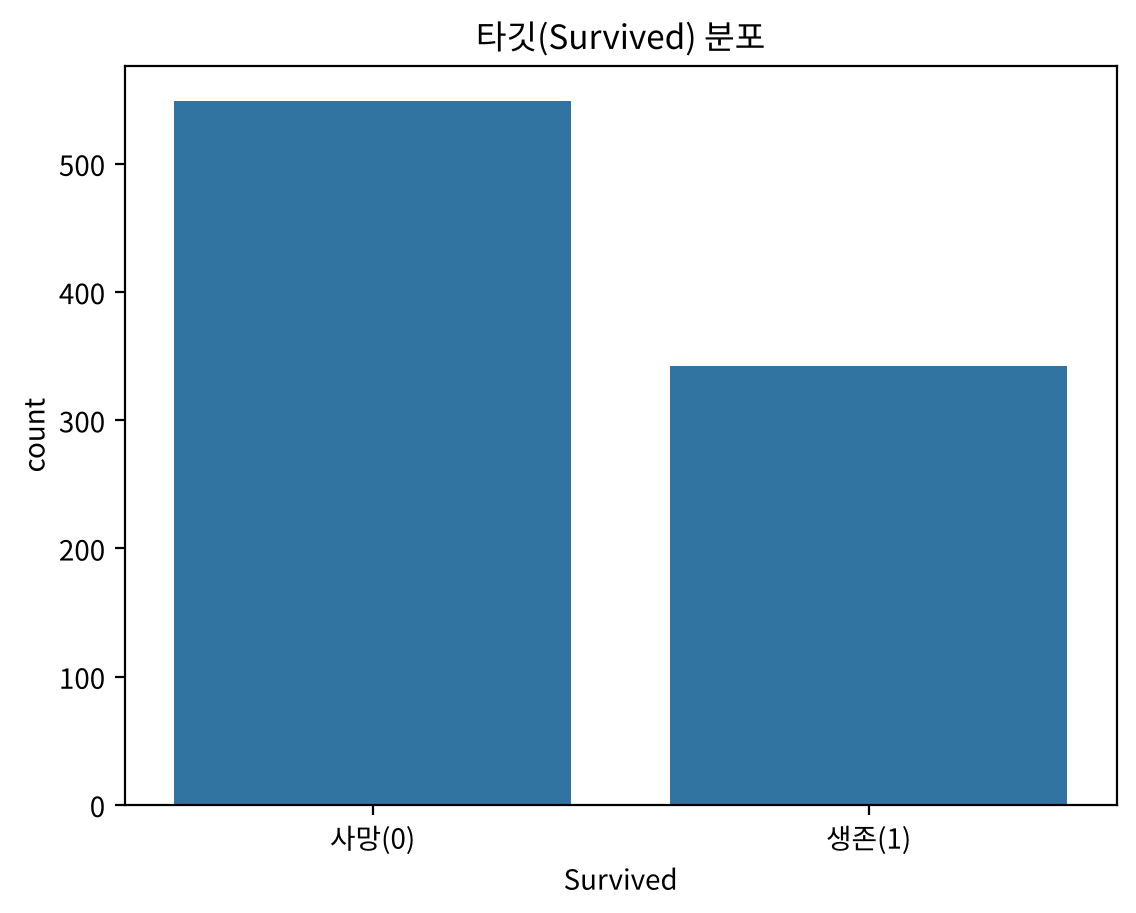

In [6]:
print(df[TARGET].value_counts())
print((df[TARGET].value_counts(normalize=True) * 100).round(1).astype(str) + " %")
ax = sns.countplot(data=df, x=TARGET)
ax.set_xticklabels(["사망(0)", "생존(1)"]); plt.title("타깃(Survived) 분포"); plt.show()

### 2-3. 변수 분포 시각화 (Histogram)

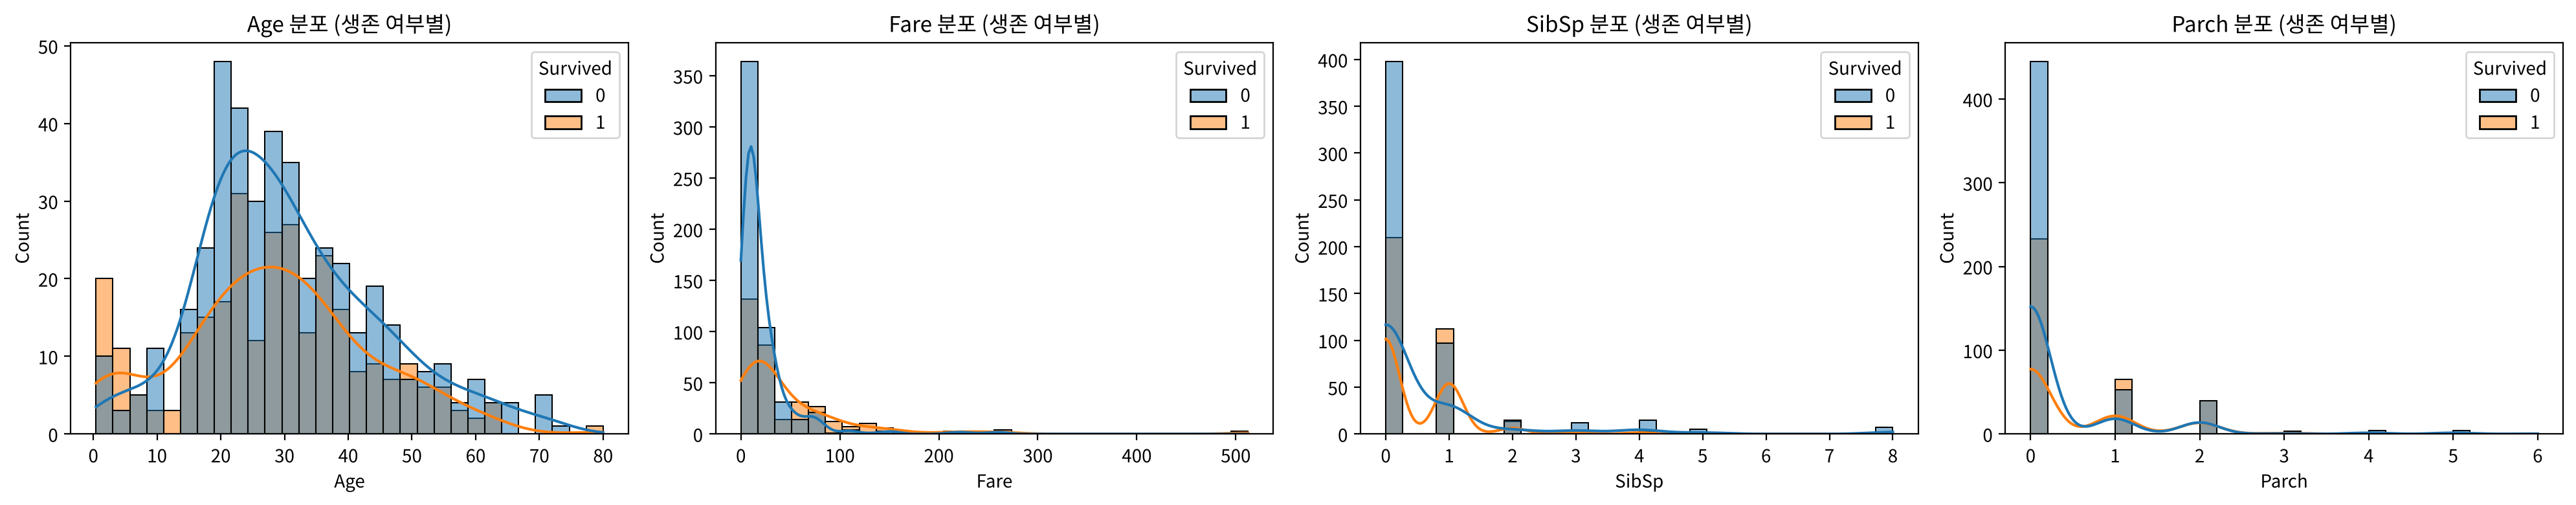

왜도(skewness):
Age      0.39
Fare     4.79
SibSp    3.70
Parch    2.75
dtype: float64


In [7]:
num_cols_raw = ["Age", "Fare", "SibSp", "Parch"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, num_cols_raw):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, ax=ax, bins=30)
    ax.set_title(f"{col} 분포 (생존 여부별)")
plt.tight_layout(); plt.show()
print("왜도(skewness):"); print(df[num_cols_raw].skew().round(2))

### 2-4. 범주형 변수 vs 생존율 (Barplot)

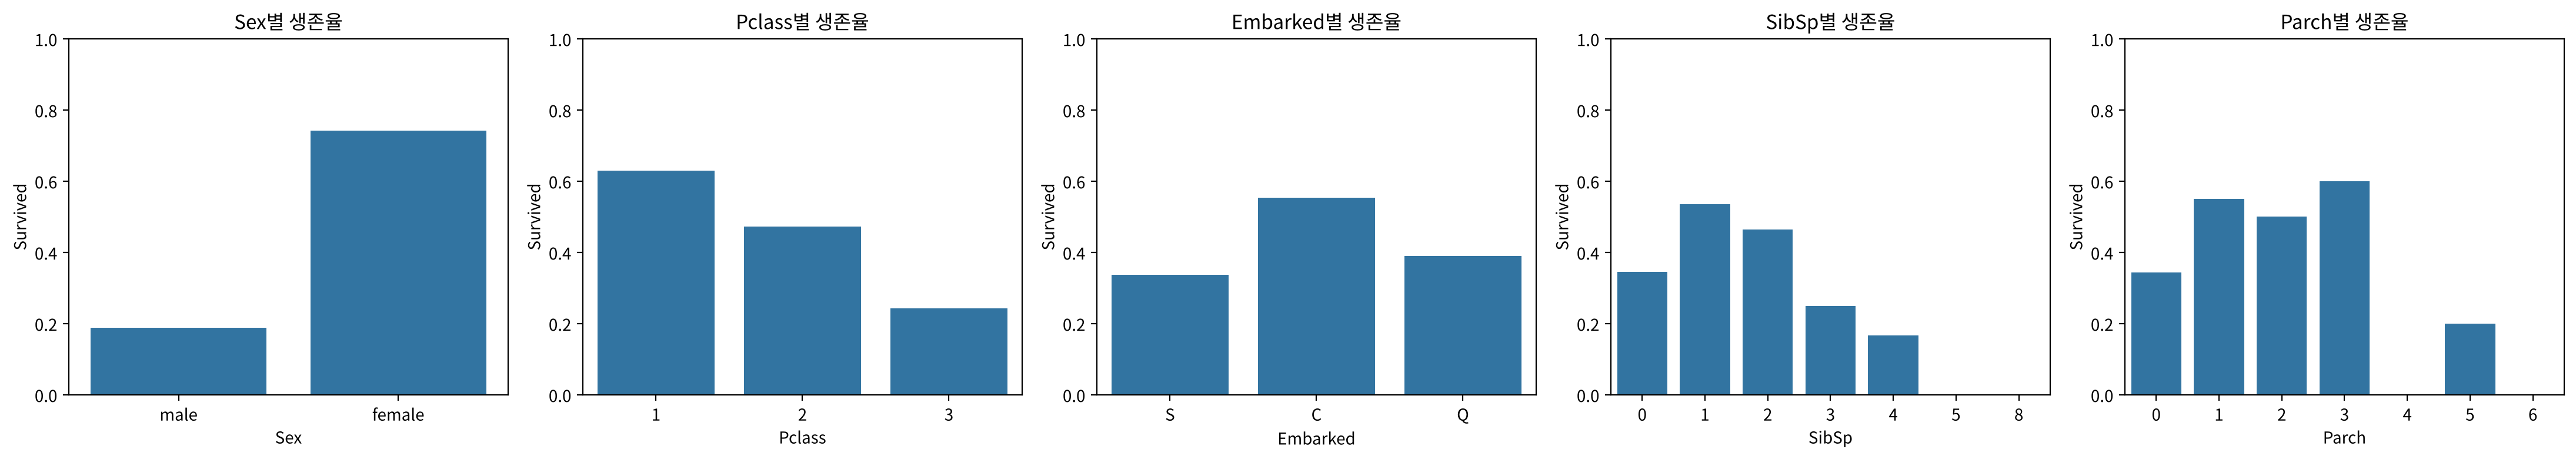

In [8]:
cat_cols_raw = ["Sex", "Pclass", "Embarked", "SibSp", "Parch"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, cat_cols_raw):
    sns.barplot(data=df, x=col, y=TARGET, ax=ax, errorbar=None)
    ax.set_title(f"{col}별 생존율"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 2-5. 이상치 탐색 (Boxplot + IQR)

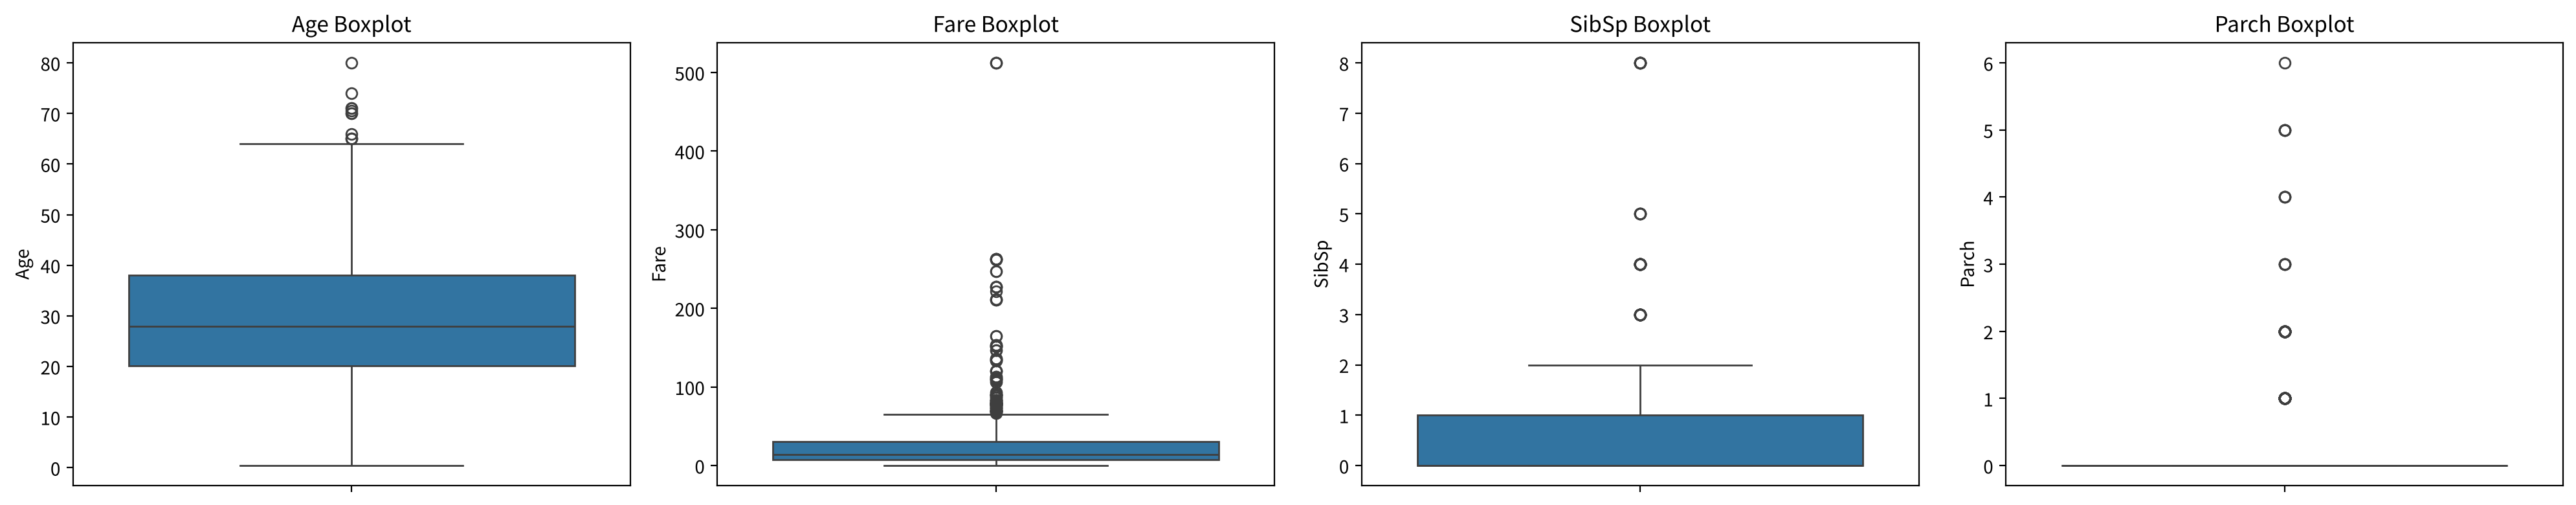

,이상치 수,하한,상한,이상치 비율(%)
컬럼,,,,
Age,11,-6.69,64.81,1.2
Fare,116,-26.72,65.63,13.0
SibSp,46,-1.50,2.50,5.2
Parch,213,0.00,0.00,23.9


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, num_cols_raw):
    sns.boxplot(data=df, y=col, ax=ax); ax.set_title(f"{col} Boxplot")
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

out = pd.DataFrame([(c, *iqr_outliers(df[c].dropna())) for c in num_cols_raw],
                   columns=["컬럼", "이상치 수", "하한", "상한"]).set_index("컬럼")
out["이상치 비율(%)"] = (out["이상치 수"] / len(df) * 100).round(1)
out.round(2)

> Fare의 이상치(예: 512 달러)는 실제 1등석 고가 티켓이라 **오류가 아닌 실제 값**으로 판단해 제거하지 않고, 대신 **RobustScaler**(중앙값·IQR 기준) 실험으로 영향을 비교한다.

### 2-6. 상관관계 분석 (Heatmap)

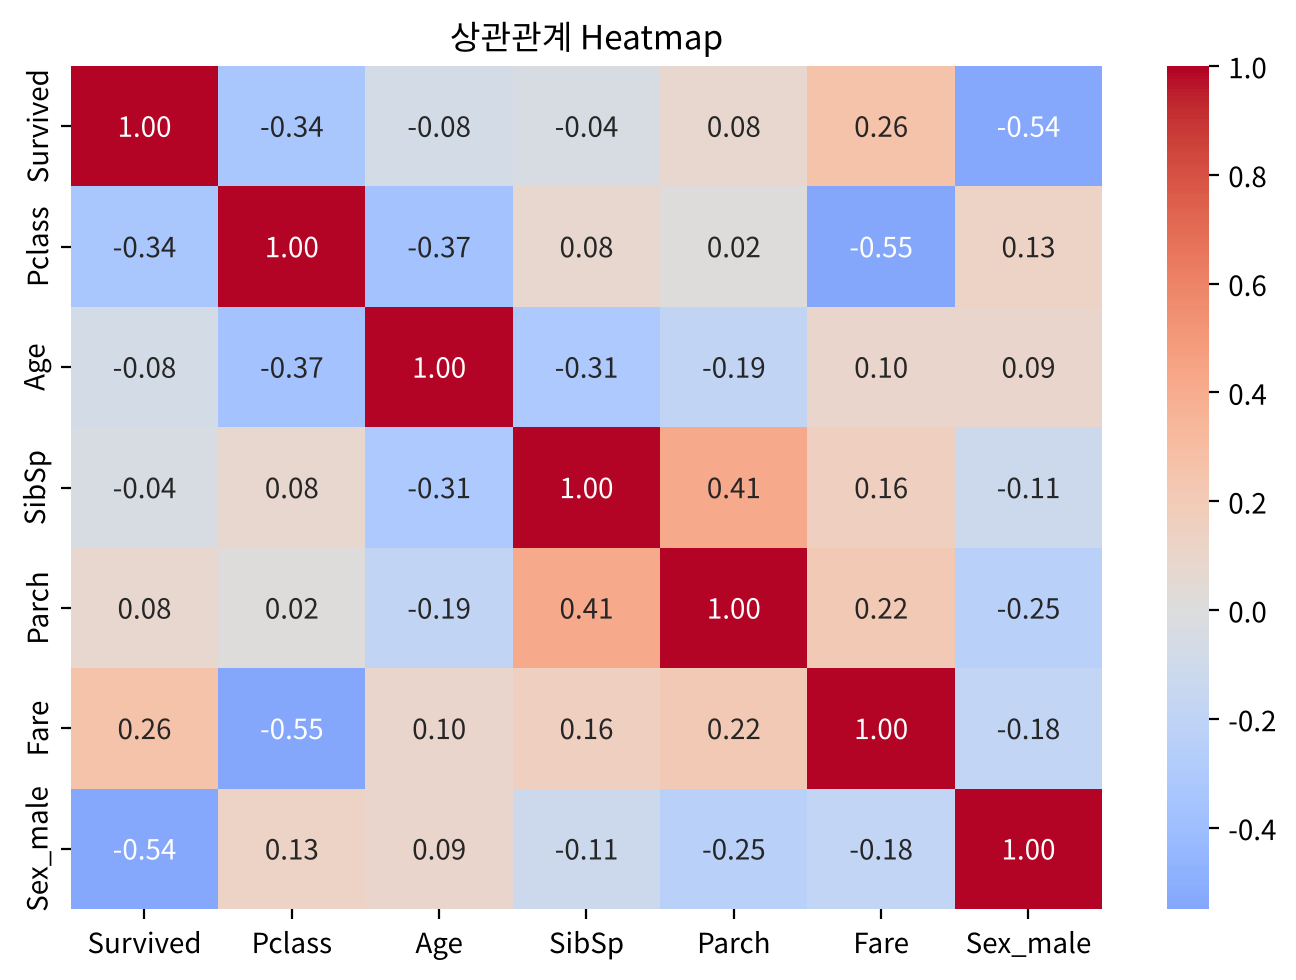

Sex_male   -0.543
Pclass     -0.338
Fare        0.257
Parch       0.082
Age        -0.077
SibSp      -0.035
Name: Survived, dtype: float64


In [10]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].copy()
corr_df["Sex_male"] = (df["Sex"] == "male").astype(int)
plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("상관관계 Heatmap"); plt.tight_layout(); plt.show()
print(corr_df.corr()["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3))

### 2-7. EDA 분석 결과
**데이터 품질 문제**
- `Cabin` 결측 약 77% → 값 자체로는 사용 어렵고, "객실 정보 유무(HasCabin)"로 변환
- `Age` 결측 약 20% → 대체(imputation) 전략 비교 필요 (STEP 3-1)
- `Embarked` 결측 2건 → 최빈값 대체
- `Fare`는 오른쪽으로 크게 치우침(왜도 약 4.8), IQR 기준 이상치 다수 → 스케일러 비교 (STEP 3-3)

**불균형 여부**
- 사망 61.6% / 생존 38.4% → 심한 불균형은 아니지만 Accuracy만 보지 않고 Precision·Recall·F1·ROC-AUC를 함께 확인

**주요 변수 특징**
- `Sex`: 여성 생존율 약 74%, 남성 약 19% → 가장 강한 변수
- `Pclass`: 1등석일수록 생존율 높음 (Survived와 상관 -0.34)
- `Fare`: 생존과 양의 상관 (0.26), Pclass와 얽혀 있음
- `SibSp`/`Parch`: 가족이 1~3명일 때 생존율이 높고 혼자이거나 대가족이면 낮음 → `FamilySize` 파생 근거

## STEP 03. 특성 공학 파이프라인 구현
### 3-4. 파생 변수 생성 (먼저 정의 — 이후 모든 실험에 사용)
| 파생 변수 | 만드는 법 | 근거 |
|---|---|---|
| `FamilySize` | SibSp + Parch + 1 | EDA에서 가족 규모에 따라 생존율이 달라짐 |
| `IsAlone` | FamilySize == 1 | 혼자 탑승 시 생존율 낮음 |
| `FarePerPerson` | Fare / FamilySize | 단체 티켓 운임을 1인 기준으로 환산 |
| `AgeGroup` | Age를 Child/Teen/Adult/Middle/Senior로 구간화 (결측은 Unknown) | 나이의 비선형 효과 (어린이 우선 구조) |
| `Title` | Name에서 호칭(Mr/Mrs/Miss/Master/Rare) 추출 | 성별·나이·신분 정보 포함 |
| `HasCabin` | Cabin 결측 여부 | 결측 자체가 객실 등급 정보를 담음 |

,Name,Title,SibSp,Parch,FamilySize,IsAlone,Fare,FarePerPerson,Age,AgeGroup,HasCabin
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0,7.2500,3.62500,22.0,Adult,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,1,0,2,0,71.2833,35.64165,38.0,Middle,1
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1,7.9250,7.92500,26.0,Adult,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0,53.1000,26.55000,35.0,Adult,1
4,"Allen, Mr. William Henry",Mr,0,0,1,1,8.0500,8.05000,35.0,Adult,0
5,"Moran, Mr. James",Mr,0,0,1,1,8.4583,8.45830,NaN,Unknown,0
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1,51.8625,51.86250,54.0,Middle,1
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0,21.0750,4.21500,2.0,Child,0


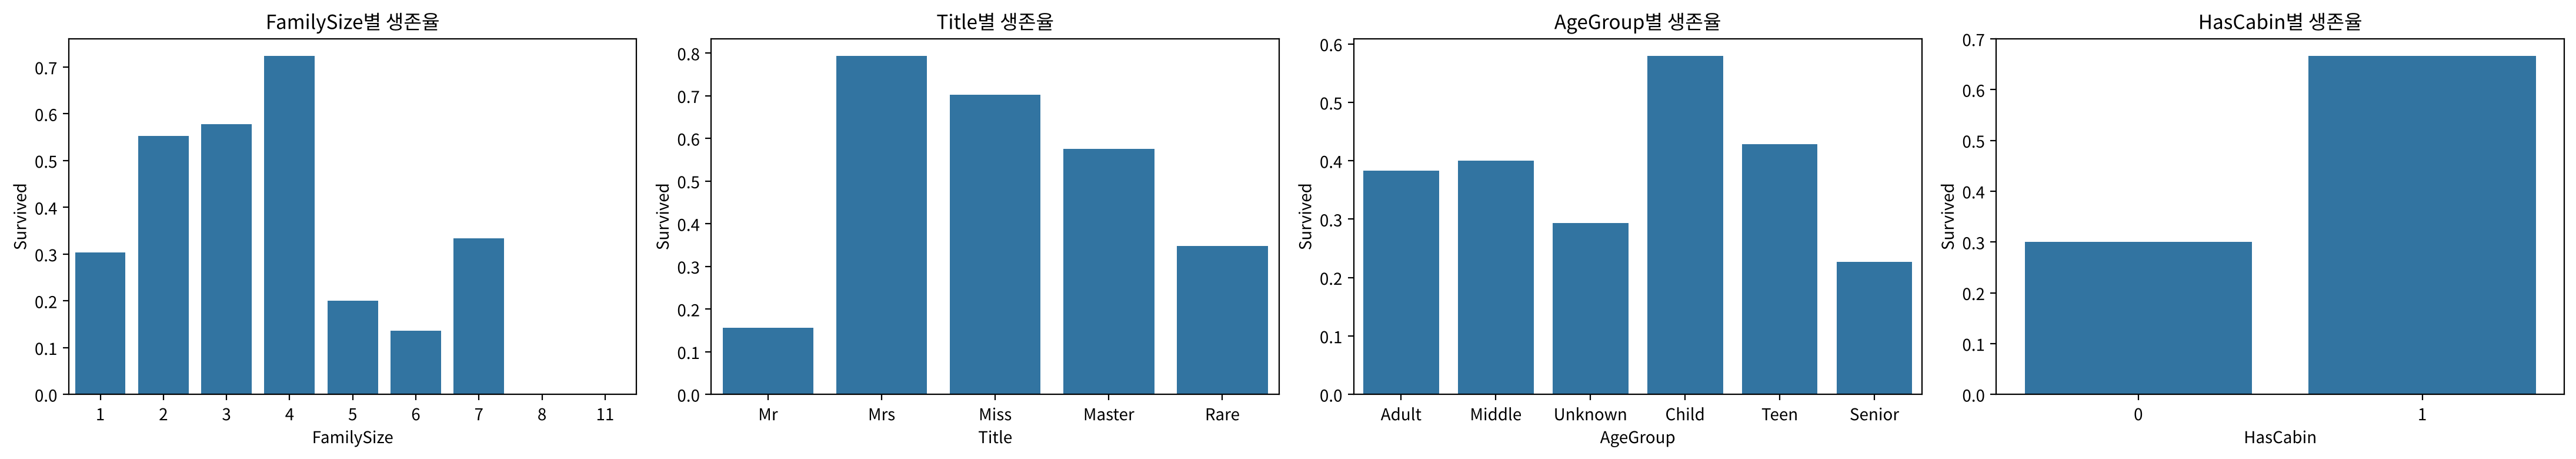

In [11]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["FarePerPerson"] = d["Fare"] / d["FamilySize"]
    d["AgeGroup"] = pd.cut(d["Age"], bins=[0, 12, 18, 35, 60, 120],
                           labels=["Child", "Teen", "Adult", "Middle", "Senior"]).astype(object)
    d["AgeGroup"] = d["AgeGroup"].fillna("Unknown")
    d["Title"] = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    d["Title"] = d["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    d.loc[~d["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Title"] = "Rare"
    d["HasCabin"] = d["Cabin"].notna().astype(int)
    return d

data = add_features(df)
display(data[["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone",
              "Fare", "FarePerPerson", "Age", "AgeGroup", "HasCabin"]].head(8))

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, col in zip(axes, ["FamilySize", "Title", "AgeGroup", "HasCabin"]):
    sns.barplot(data=data, x=col, y=TARGET, ax=ax, errorbar=None); ax.set_title(f"{col}별 생존율")
plt.tight_layout(); plt.show()

### 공통 실험 도구
- 모든 전처리를 **scikit-learn `Pipeline` + `ColumnTransformer`** 안에 넣어, 교차검증 시 **학습 fold에서만 fit** → 데이터 누수 방지 (가산점: Pipeline 객체 활용)
- 평가: **Stratified 5-Fold 교차검증**, 지표 Accuracy / Precision / Recall / F1 / ROC-AUC
- 과적합 확인용으로 학습 점수와 검증 점수의 차이(Gap)도 기록

In [12]:
ORIG_NUM = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
ORIG_CAT = ["Sex", "Embarked"]
FE_NUM = ORIG_NUM + ["FamilySize", "IsAlone", "FarePerPerson", "HasCabin"]
FE_CAT = ORIG_CAT + ["Title", "AgeGroup"]

SCALERS = {"Standard": StandardScaler, "MinMax": MinMaxScaler, "Robust": RobustScaler, None: None}

def make_models():
    return {
        "LogReg": LogisticRegression(max_iter=2000),
        "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=7, random_state=SEED, n_jobs=-1),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                                 eval_metric="logloss", random_state=SEED, n_jobs=-1),
        "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15,
                                   random_state=SEED, verbose=-1),
    }

def build_pipeline(model, impute="median", encode="onehot", scale="Standard",
                   select_top=None, num_cols=FE_NUM, cat_cols=FE_CAT):
    num_steps = [("impute", SimpleImputer(strategy=impute))]
    if scale:
        num_steps.append(("scale", SCALERS[scale]()))
    enc = (OneHotEncoder(handle_unknown="ignore", sparse_output=False) if encode == "onehot"
           else OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    cat_steps = [("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)]
    prep = ColumnTransformer([("num", Pipeline(num_steps), num_cols),
                              ("cat", Pipeline(cat_steps), cat_cols)])
    steps = [("prep", prep)]
    if select_top:   # Random Forest 중요도 상위 N개만 남김
        steps.append(("select", SelectFromModel(
            RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
            max_features=select_top, threshold=-np.inf)))
    steps.append(("model", model))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def evaluate(pipe, X, y):
    s = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, return_train_score=True)
    r = {m: s[f"test_{m}"].mean() for m in SCORING}
    r["train_acc"] = s["train_accuracy"].mean()
    r["gap(train-val)"] = r["train_acc"] - r["accuracy"]
    return r

def run_experiments(configs, X=None, y=None):
    """configs: {실험명: build_pipeline 인자 dict 또는 (X, y, 인자 dict)}"""
    rows = []
    for name, cfg in configs.items():
        Xi, yi, kw = cfg if isinstance(cfg, tuple) else (X, y, cfg)
        for mname, model in make_models().items():
            rows.append({"실험": name, "모델": mname, **evaluate(build_pipeline(model, **kw), Xi, yi)})
    return pd.DataFrame(rows)

def show(res, metric="accuracy", title=""):
    piv = res.pivot(index="실험", columns="모델", values=metric).loc[res["실험"].unique()]
    display(piv.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce").set_caption(f"{title} — {metric}"))
    piv.plot(kind="bar", figsize=(10, 4)); plt.ylim(piv.values.min() - 0.03, piv.values.max() + 0.02)
    plt.title(f"{title} ({metric}, 5-Fold CV)"); plt.xticks(rotation=0); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.show()

X, y = data, data[TARGET]

### 3-1. 결측치 처리 비교 (Mean / Median / Most Frequent / Drop NA)
- 고정: One-Hot 인코딩, StandardScaler, 파생 변수 사용, 변수 선택 없음
- 범주형(`Embarked`)은 평균·중앙값을 쓸 수 없으므로 모든 실험에서 최빈값으로 대체
- Drop NA는 Age 결측 행을 지운 뒤 평가 → **표본 수가 891 → 712로 줄어듦**에 유의

Drop NA 후 shape: (712, 18)


모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
Mean,0.8339,0.8238,0.8350,0.8350
Median,0.8305,0.8238,0.8372,0.8327
Most Frequent,0.8361,0.8249,0.8361,0.8339
Drop NA,0.8203,0.8173,0.8174,0.8217


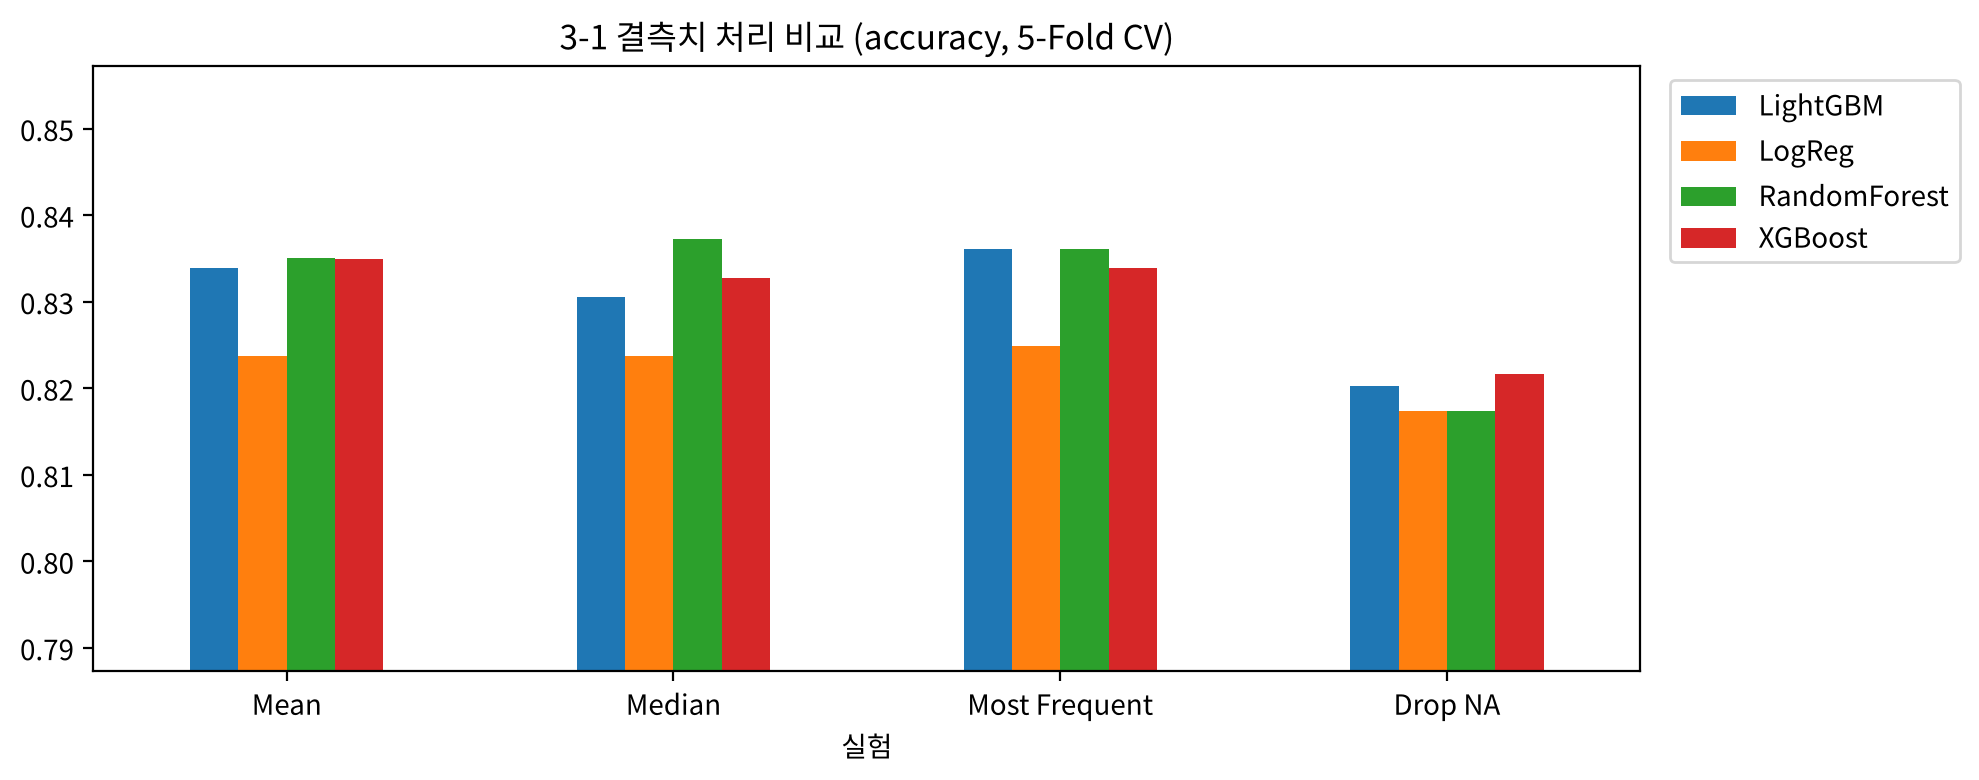

,실험,모델,accuracy,precision,recall,f1,roc_auc,train_acc,gap(train-val)
0,Mean,LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8361,0.0124
1,Mean,RandomForest,0.8350,0.8124,0.7426,0.7750,0.8818,0.9012,0.0662
2,Mean,XGBoost,0.8350,0.8110,0.7457,0.7763,0.8813,0.9192,0.0842
3,Mean,LightGBM,0.8339,0.7983,0.7602,0.7785,0.8823,0.9405,0.1066
4,Median,LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8361,0.0124
5,Median,RandomForest,0.8372,0.8178,0.7427,0.7775,0.8811,0.8998,0.0626
6,Median,XGBoost,0.8327,0.8053,0.7456,0.7739,0.8844,0.9203,0.0876
7,Median,LightGBM,0.8305,0.7979,0.7486,0.7720,0.8815,0.9377,0.1072
8,Most Frequent,LogReg,0.8249,0.7873,0.7454,0.7652,0.8705,0.8367,0.0118
9,Most Frequent,RandomForest,0.8361,0.8156,0.7427,0.7763,0.8808,0.9018,0.0657


In [13]:
data_dropna = data.dropna(subset=["Age", "Embarked"])
print("Drop NA 후 shape:", data_dropna.shape)

res_impute = run_experiments({
    "Mean":          dict(impute="mean"),
    "Median":        dict(impute="median"),
    "Most Frequent": dict(impute="most_frequent"),
    "Drop NA":       (data_dropna, data_dropna[TARGET], dict(impute="median")),
}, X, y)
show(res_impute, title="3-1 결측치 처리 비교")
res_impute.round(4)

### 3-2. 범주형 인코딩 비교 (Label vs One-Hot)
- 고정: Median 대체, StandardScaler
- Label Encoding은 범주를 0,1,2… 정수로 바꿈 (`OrdinalEncoder` 사용 — sklearn의 `LabelEncoder`는 타깃용이라 Pipeline에서 X 변환에 쓸 수 없음)

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
Label,0.8361,0.8014,0.8372,0.8328
One-Hot,0.8305,0.8238,0.8372,0.8327


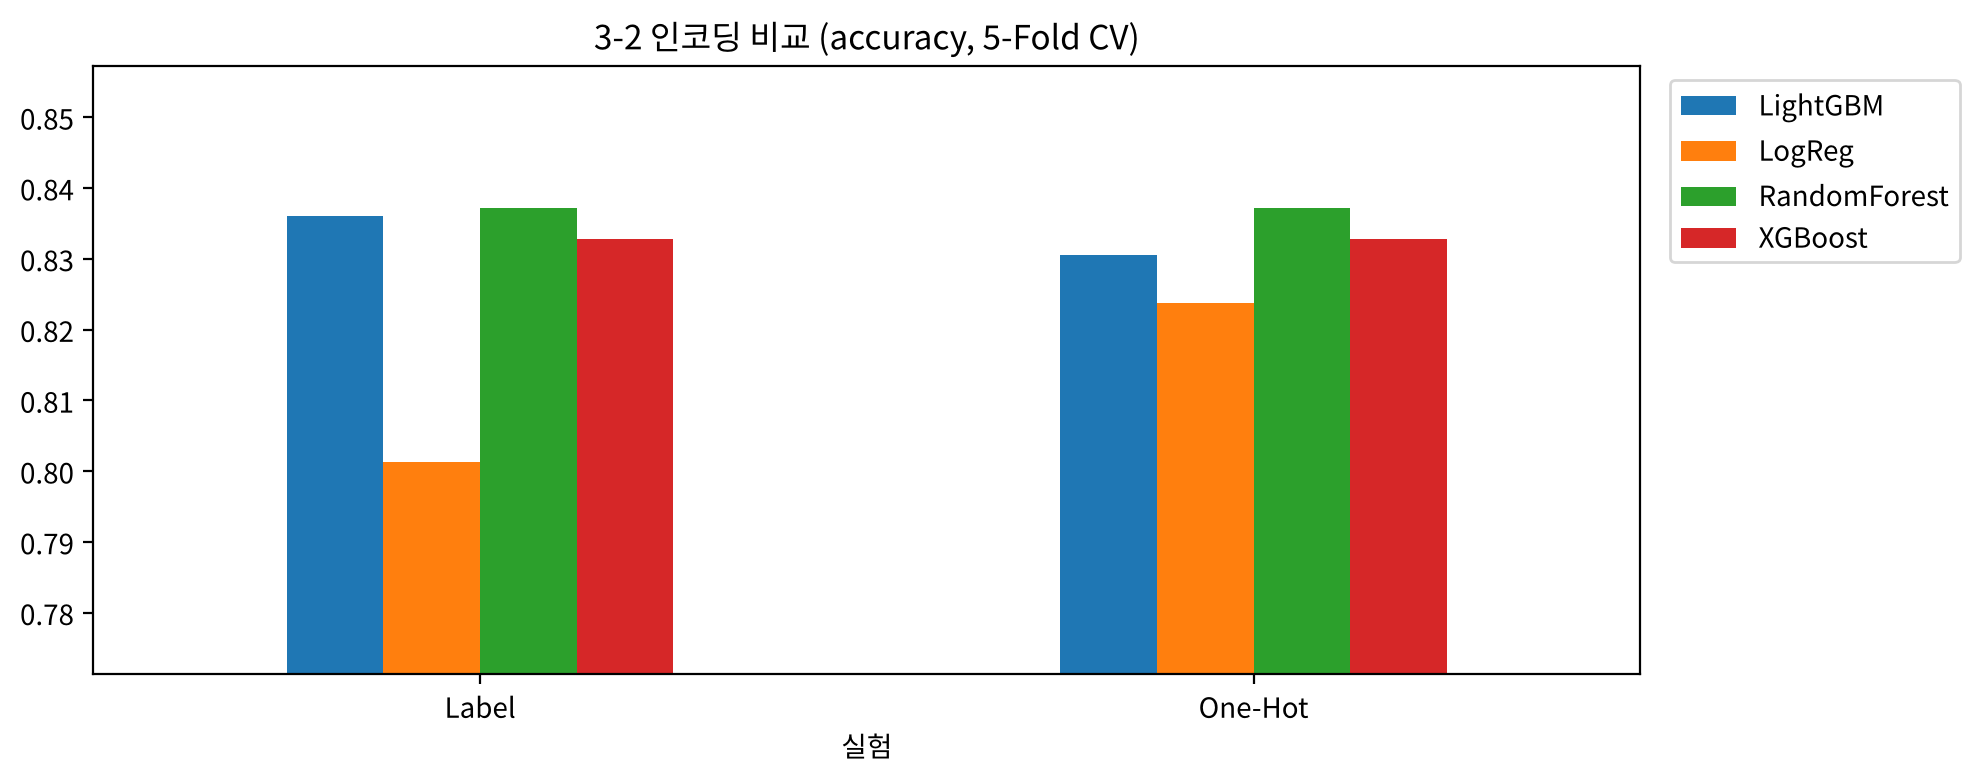

,실험,모델,accuracy,precision,recall,f1,roc_auc,train_acc,gap(train-val)
0,Label,LogReg,0.8014,0.7566,0.7104,0.7322,0.8603,0.8117,0.0104
1,Label,RandomForest,0.8372,0.8182,0.7427,0.7774,0.8808,0.9161,0.0789
2,Label,XGBoost,0.8328,0.8046,0.7456,0.7736,0.8769,0.9169,0.0842
3,Label,LightGBM,0.8361,0.8087,0.7514,0.7788,0.8807,0.9402,0.1041
4,One-Hot,LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8361,0.0124
5,One-Hot,RandomForest,0.8372,0.8178,0.7427,0.7775,0.8811,0.8998,0.0626
6,One-Hot,XGBoost,0.8327,0.8053,0.7456,0.7739,0.8844,0.9203,0.0876
7,One-Hot,LightGBM,0.8305,0.7979,0.7486,0.7720,0.8815,0.9377,0.1072


In [14]:
res_encode = run_experiments({
    "Label":   dict(encode="label"),
    "One-Hot": dict(encode="onehot"),
}, X, y)
show(res_encode, title="3-2 인코딩 비교")
res_encode.round(4)

### 3-3. 스케일링 비교 (없음 / Standard / MinMax / Robust)
- 고정: Median 대체, One-Hot

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
None,0.8294,0.8238,0.8372,0.8327
Standard,0.8305,0.8238,0.8372,0.8327
MinMax,0.8294,0.8316,0.8372,0.8327
Robust,0.8327,0.8238,0.8372,0.8327


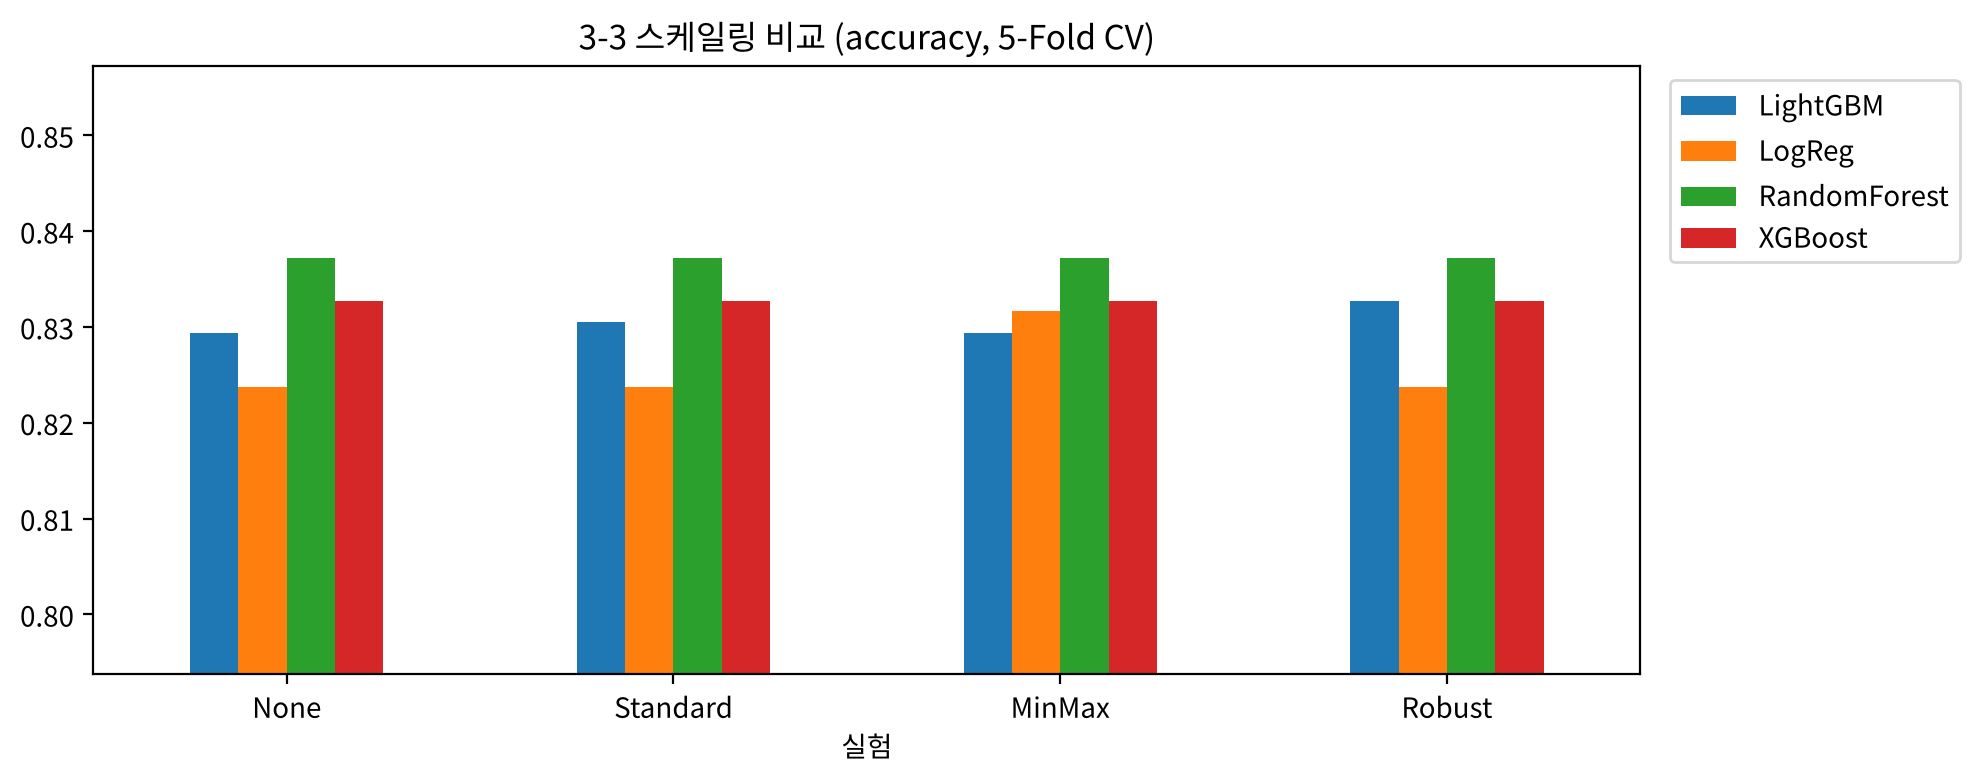

,실험,모델,accuracy,precision,recall,f1,roc_auc,train_acc,gap(train-val)
0,None,LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8359,0.0121
1,None,RandomForest,0.8372,0.8158,0.7456,0.7781,0.8811,0.9001,0.0629
2,None,XGBoost,0.8327,0.8053,0.7456,0.7739,0.8844,0.9203,0.0876
3,None,LightGBM,0.8294,0.7920,0.7544,0.7723,0.8809,0.9397,0.1103
4,Standard,LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8361,0.0124
5,Standard,RandomForest,0.8372,0.8178,0.7427,0.7775,0.8811,0.8998,0.0626
6,Standard,XGBoost,0.8327,0.8053,0.7456,0.7739,0.8844,0.9203,0.0876
7,Standard,LightGBM,0.8305,0.7979,0.7486,0.7720,0.8815,0.9377,0.1072
8,MinMax,LogReg,0.8316,0.7965,0.7542,0.7745,0.8733,0.8432,0.0115
9,MinMax,RandomForest,0.8372,0.8158,0.7456,0.7781,0.8818,0.8998,0.0626


In [15]:
res_scale = run_experiments({
    "None":     dict(scale=None),
    "Standard": dict(scale="Standard"),
    "MinMax":   dict(scale="MinMax"),
    "Robust":   dict(scale="Robust"),
}, X, y)
show(res_scale, title="3-3 스케일링 비교")
res_scale.round(4)

### 3-4 (계속). 파생 변수 효과 비교
- 고정: Median, One-Hot, StandardScaler
- 원본 변수만 사용 vs 원본 + 파생 변수

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
원본 변수만,0.8429,0.7935,0.8384,0.8372
원본+파생 변수,0.8305,0.8238,0.8372,0.8327


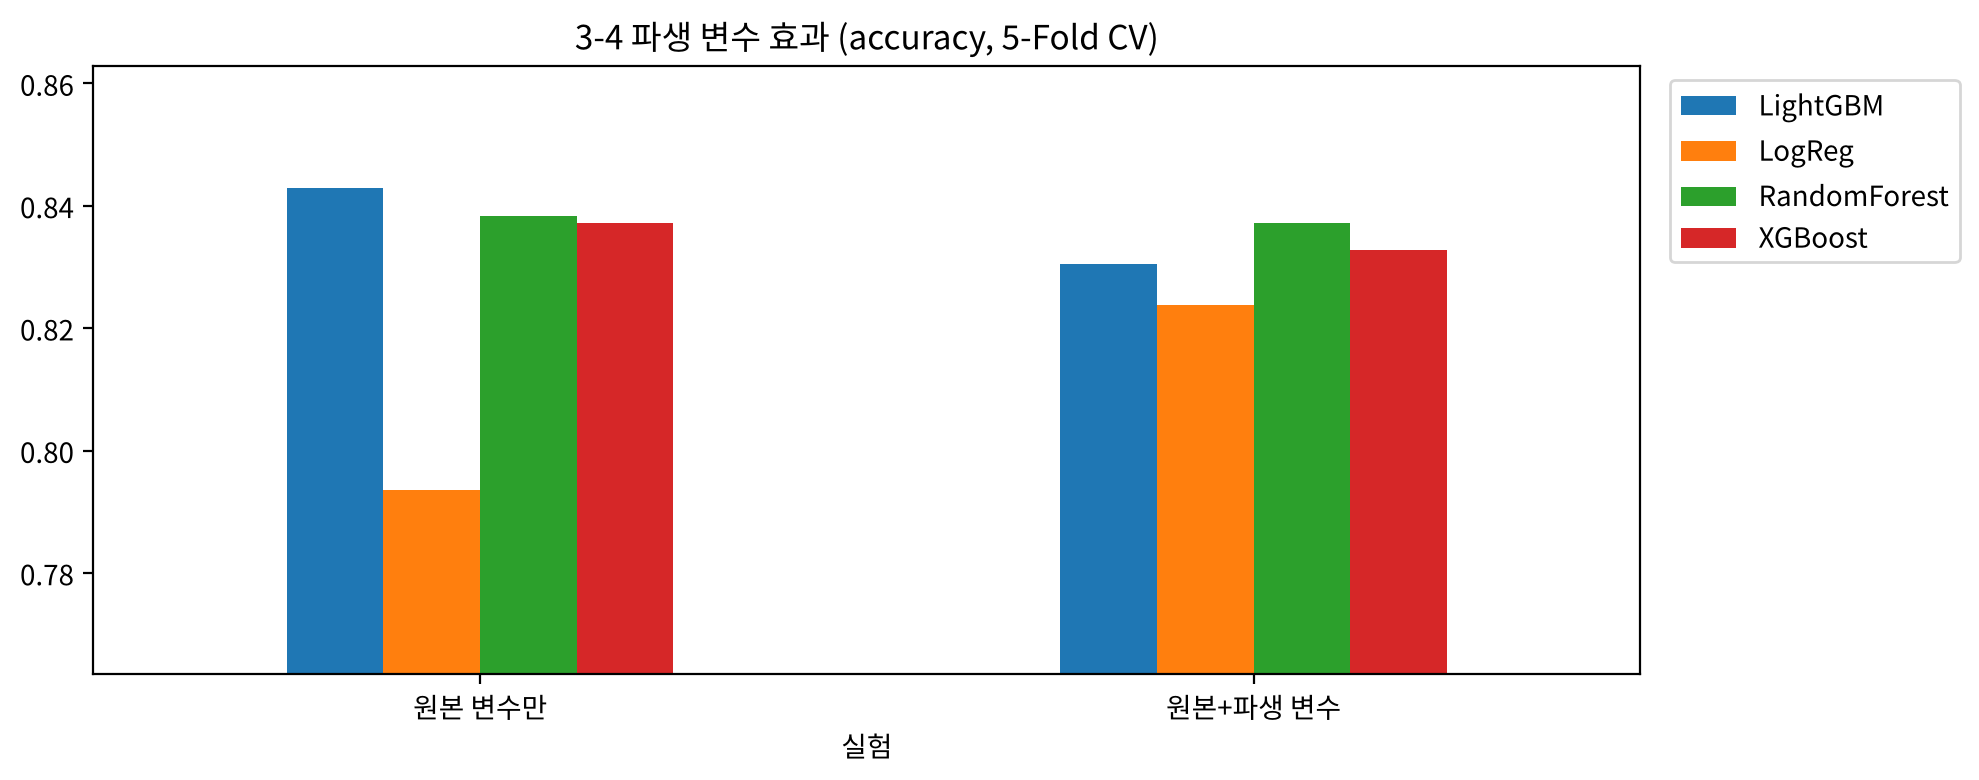

,실험,모델,accuracy,precision,recall,f1,roc_auc,train_acc,gap(train-val)
0,원본 변수만,LogReg,0.7935,0.7441,0.7074,0.7242,0.8520,0.8042,0.0106
1,원본 변수만,RandomForest,0.8384,0.8578,0.6960,0.7674,0.8738,0.8945,0.0561
2,원본 변수만,XGBoost,0.8372,0.8332,0.7191,0.7716,0.8711,0.9004,0.0632
3,원본 변수만,LightGBM,0.8429,0.8244,0.7515,0.7857,0.8820,0.9167,0.0738
4,원본+파생 변수,LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8361,0.0124
5,원본+파생 변수,RandomForest,0.8372,0.8178,0.7427,0.7775,0.8811,0.8998,0.0626
6,원본+파생 변수,XGBoost,0.8327,0.8053,0.7456,0.7739,0.8844,0.9203,0.0876
7,원본+파생 변수,LightGBM,0.8305,0.7979,0.7486,0.7720,0.8815,0.9377,0.1072


In [16]:
res_fe = run_experiments({
    "원본 변수만":     dict(num_cols=ORIG_NUM, cat_cols=ORIG_CAT),
    "원본+파생 변수": dict(num_cols=FE_NUM, cat_cols=FE_CAT),
}, X, y)
show(res_fe, title="3-4 파생 변수 효과")
res_fe.round(4)

## STEP 04. 변수 선택 (Feature Selection)
- 방법: **Random Forest Feature Importance**로 중요도 상위 N개 선택
- 파이프라인 안에서 `SelectFromModel`로 fold마다 다시 계산 → 누수 없음
### 4-1. 전체 데이터 기준 변수 중요도

전처리 후 전체 변수 수: 25


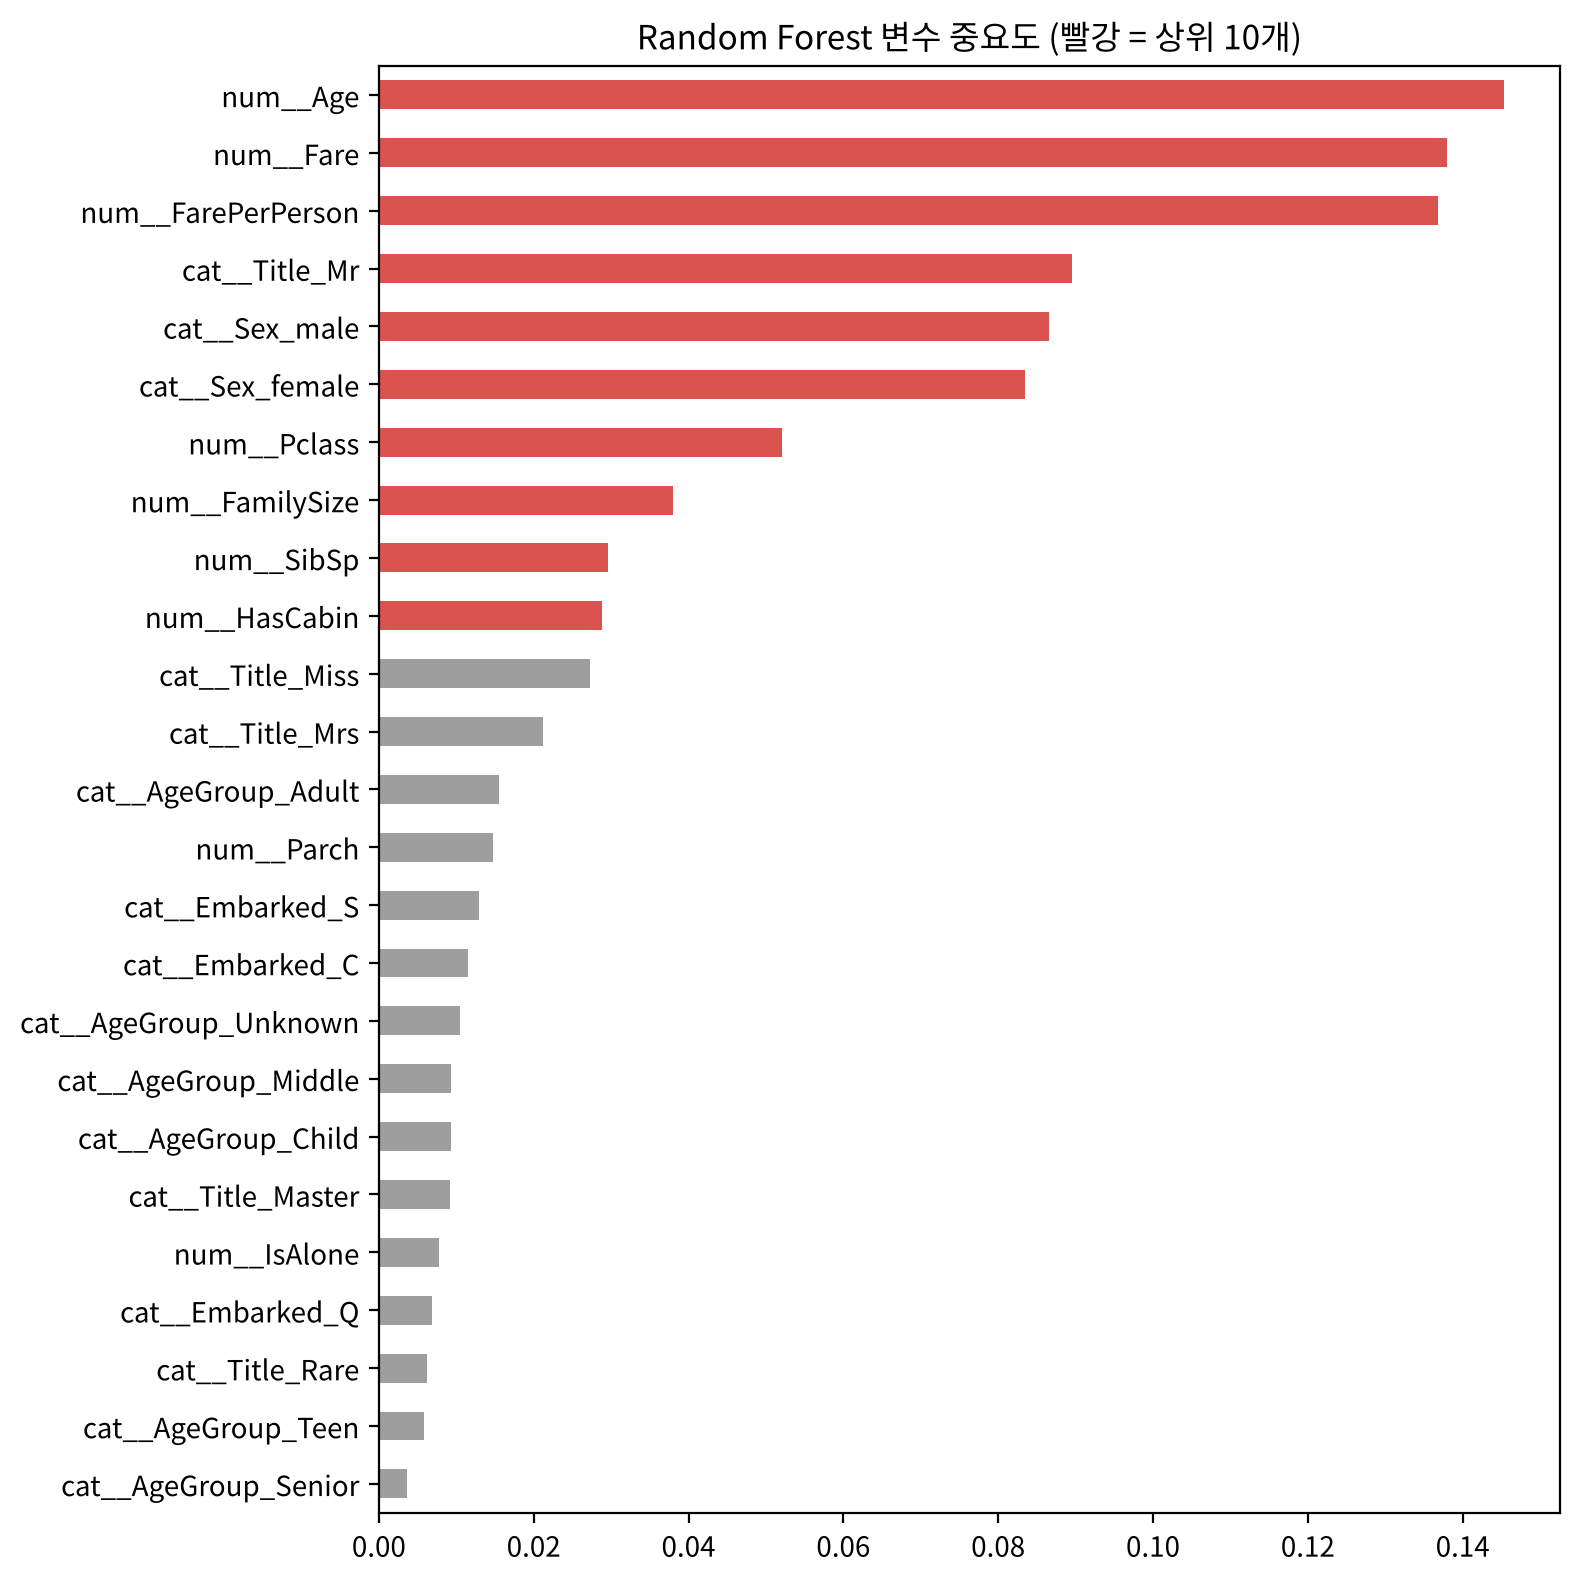

,importance
num__Age,0.1453
num__Fare,0.1380
num__FarePerPerson,0.1369
cat__Title_Mr,0.0895
cat__Sex_male,0.0865
cat__Sex_female,0.0834
num__Pclass,0.0521
num__FamilySize,0.0380
num__SibSp,0.0296
num__HasCabin,0.0288


In [17]:
fs_pipe = build_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(X, y)
feat_names = fs_pipe.named_steps["prep"].get_feature_names_out()
importances = pd.Series(fs_pipe.named_steps["model"].feature_importances_, index=feat_names).sort_values()
print("전처리 후 전체 변수 수:", len(feat_names))

plt.figure(figsize=(8, 8))
importances.plot(kind="barh", color=["#d9534f" if v >= importances.sort_values().iloc[-10] else "#9e9e9e" for v in importances])
plt.title("Random Forest 변수 중요도 (빨강 = 상위 10개)"); plt.tight_layout(); plt.show()
importances.sort_values(ascending=False).head(10).round(4).to_frame("importance")

### 4-2. 상위 N개 선택 전/후 성능 비교
- N = 전체(선택 안 함), 15, 10, 5

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
전체(25),0.8305,0.8238,0.8372,0.8327
상위 15,0.8395,0.8170,0.8316,0.8249
상위 10,0.8361,0.8069,0.8451,0.8406
상위 5,0.8215,0.7811,0.8485,0.8294


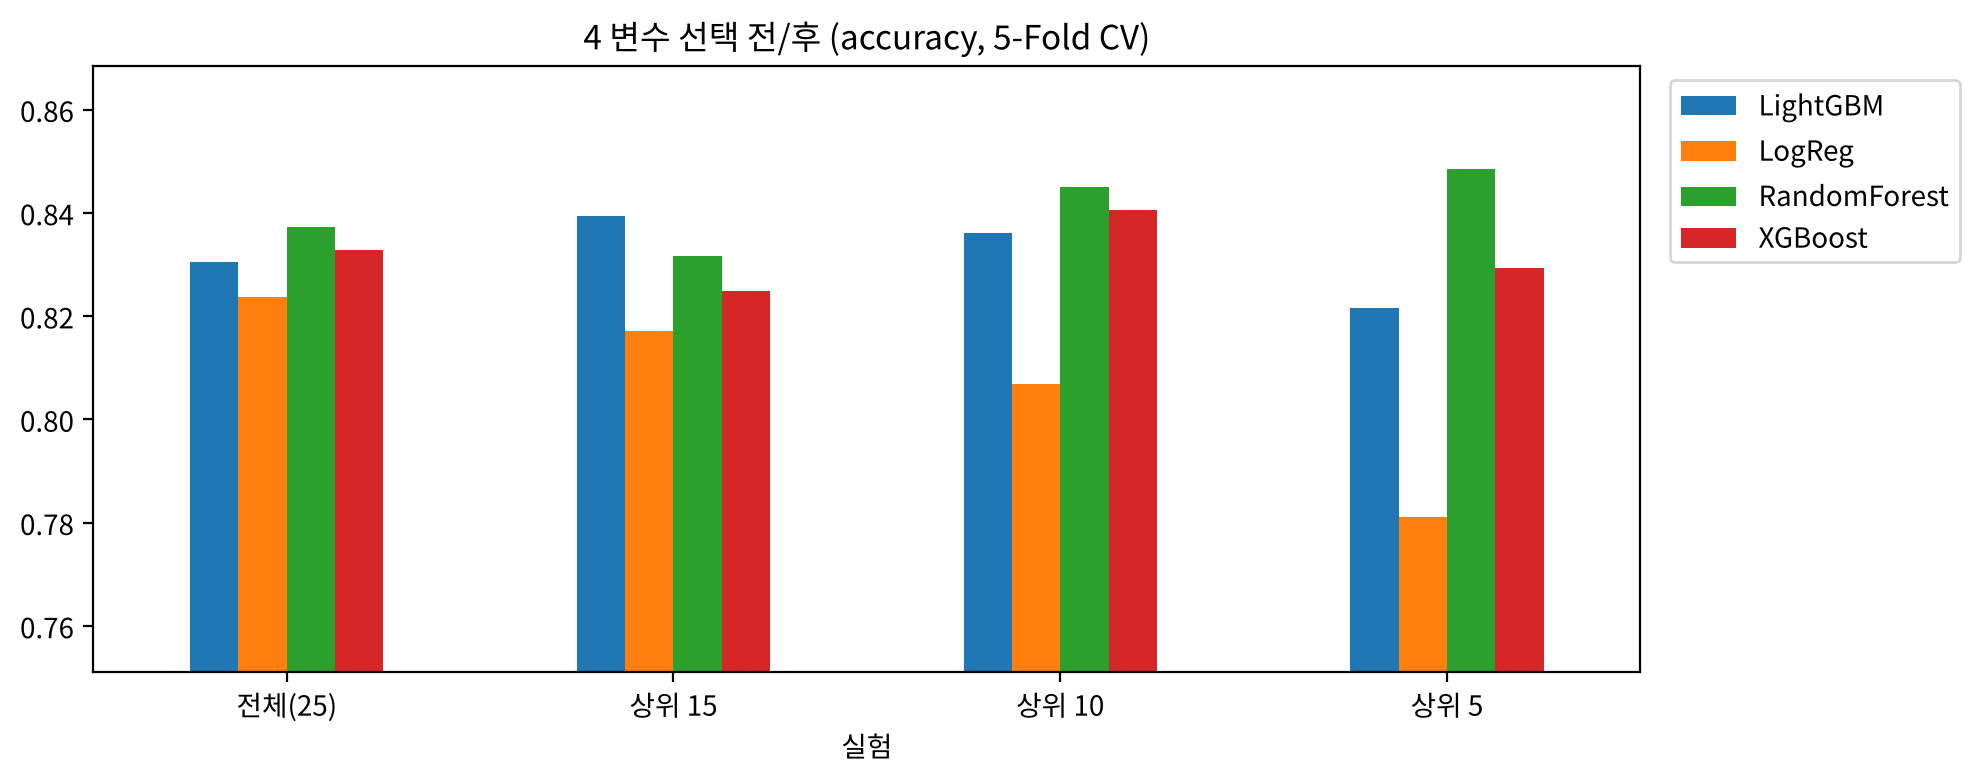

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
전체(25),0.1072,0.0124,0.0626,0.0876
상위 15,0.0977,0.0037,0.0727,0.0943
상위 10,0.0937,0.0070,0.0665,0.0721
상위 5,0.1047,0.0065,0.0618,0.0744


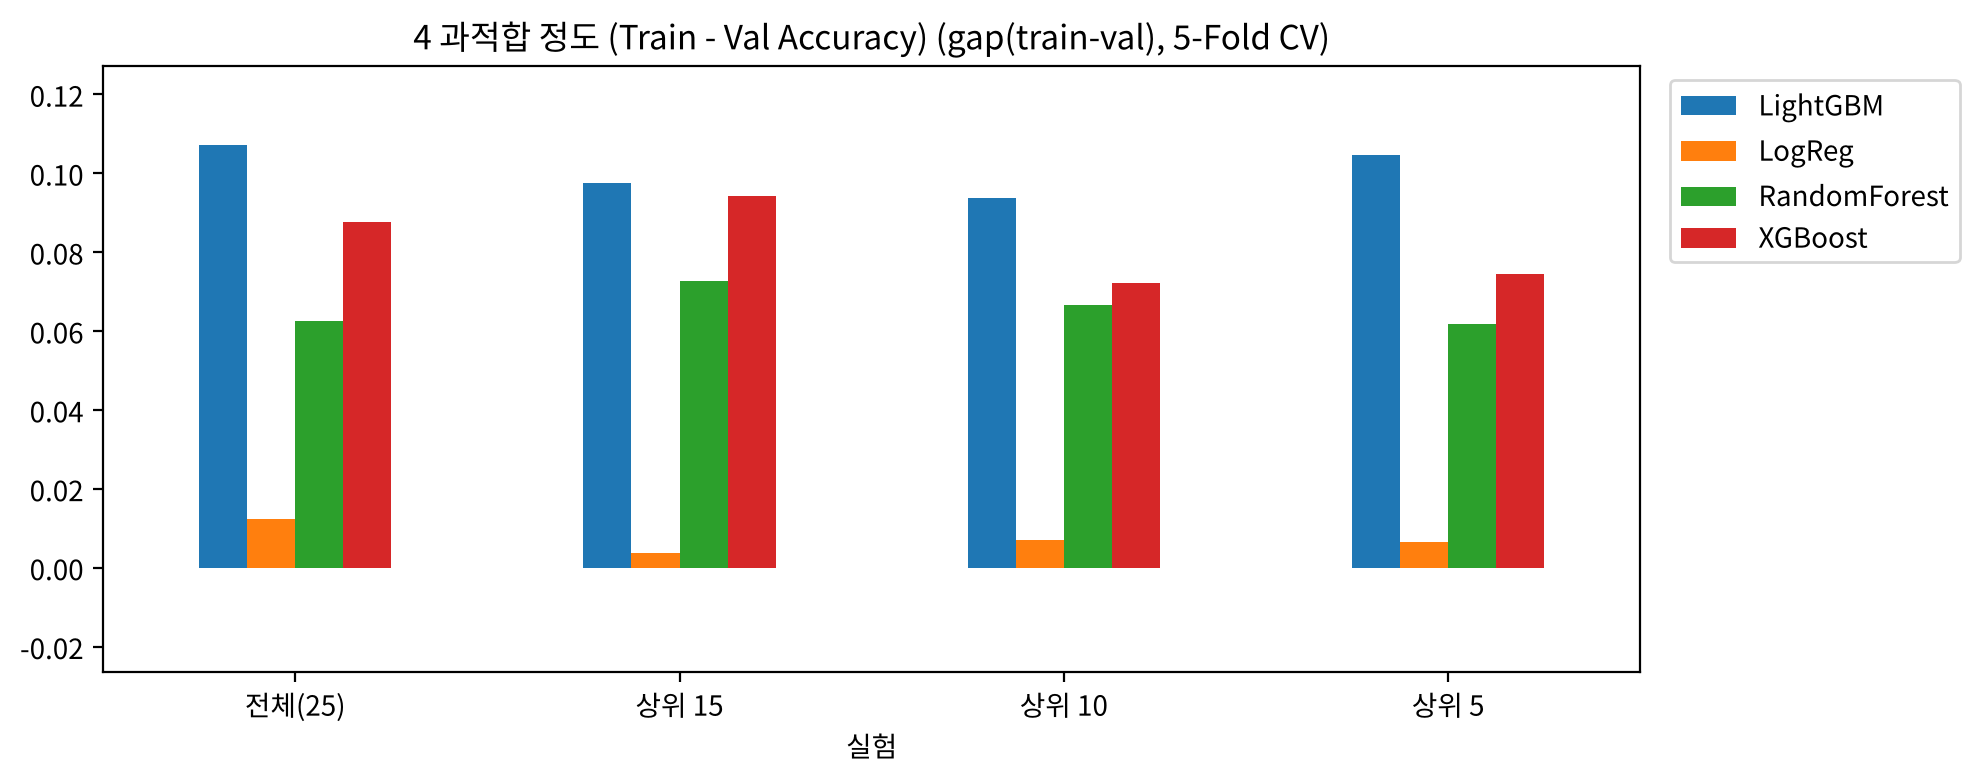

,실험,모델,accuracy,precision,recall,f1,roc_auc,train_acc,gap(train-val)
0,전체(25),LogReg,0.8238,0.7850,0.7454,0.7641,0.8705,0.8361,0.0124
1,전체(25),RandomForest,0.8372,0.8178,0.7427,0.7775,0.8811,0.8998,0.0626
2,전체(25),XGBoost,0.8327,0.8053,0.7456,0.7739,0.8844,0.9203,0.0876
3,전체(25),LightGBM,0.8305,0.7979,0.7486,0.7720,0.8815,0.9377,0.1072
4,상위 15,LogReg,0.8170,0.7703,0.7453,0.7566,0.8675,0.8207,0.0037
5,상위 15,RandomForest,0.8316,0.8126,0.7310,0.7690,0.8773,0.9043,0.0727
6,상위 15,XGBoost,0.8249,0.7914,0.7397,0.7643,0.8769,0.9192,0.0943
7,상위 15,LightGBM,0.8395,0.8065,0.7659,0.7854,0.8809,0.9371,0.0977
8,상위 10,LogReg,0.8069,0.7552,0.7337,0.7437,0.8628,0.8140,0.0070
9,상위 10,RandomForest,0.8451,0.8214,0.7630,0.7906,0.8783,0.9116,0.0665


In [18]:
n_all = len(feat_names)
res_fs = run_experiments({
    f"전체({n_all})": dict(select_top=None),
    "상위 15":  dict(select_top=15),
    "상위 10":  dict(select_top=10),
    "상위 5":   dict(select_top=5),
}, X, y)
show(res_fs, title="4 변수 선택 전/후")
show(res_fs, metric="gap(train-val)", title="4 과적합 정도 (Train - Val Accuracy)")
res_fs.round(4)

## STEP 05. 모델 학습 및 평가 — 실험 비교표 (필수)
| 실험 | 결측치 처리 | 인코딩 | 스케일링 | Feature Selection |
|---|---|---|---|---|
| Base | 없음 | 없음 | 없음 | 없음 |
| Exp-1 | Mean | One-Hot | Standard | X |
| Exp-2 | Median | Label | MinMax | O (RF 상위 10개) |
| Exp-3 | Most Frequent | One-Hot | Robust | O (RF 상위 10개) |

- **Base**: 전처리를 전혀 하지 않으므로 결측치가 없고 숫자인 원본 컬럼(`Pclass`, `SibSp`, `Parch`, `Fare`)만 그대로 사용
- Exp-1~3은 파생 변수 포함

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
Base,0.7183,0.6824,0.7228,0.7340
Exp-1,0.8339,0.8238,0.8350,0.8350
Exp-2,0.8271,0.8002,0.8327,0.8316
Exp-3,0.8339,0.8047,0.8474,0.8350


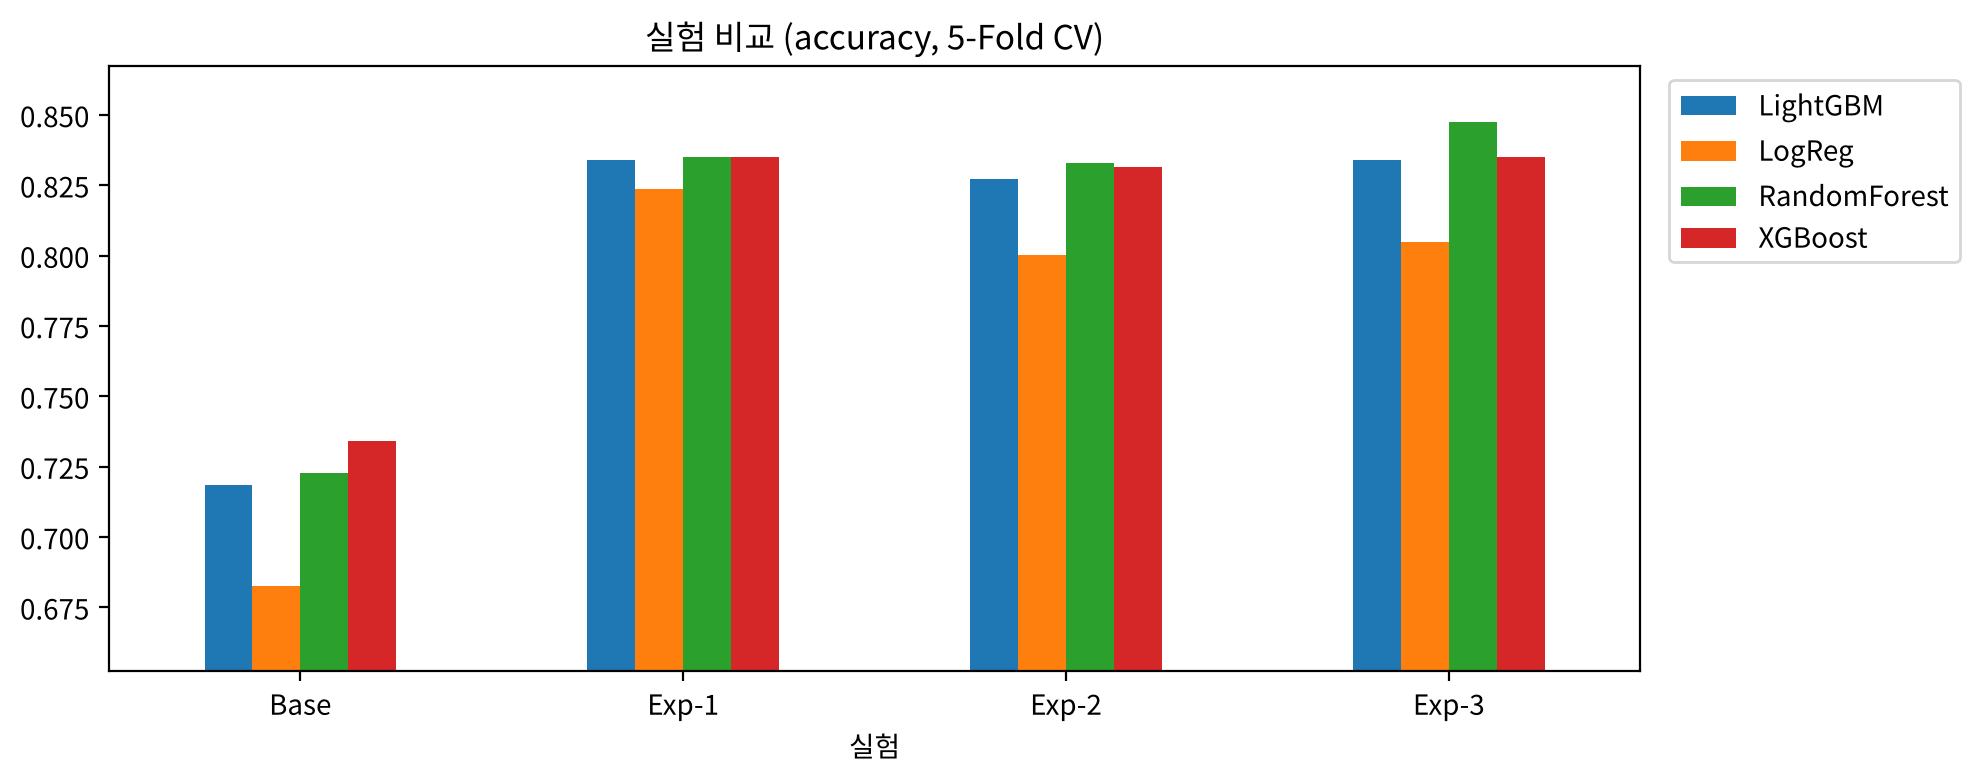

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
Base,0.5964,0.5092,0.5888,0.6034
Exp-1,0.7785,0.7641,0.7750,0.7763
Exp-2,0.7675,0.7267,0.7721,0.7711
Exp-3,0.7763,0.7408,0.7930,0.7758


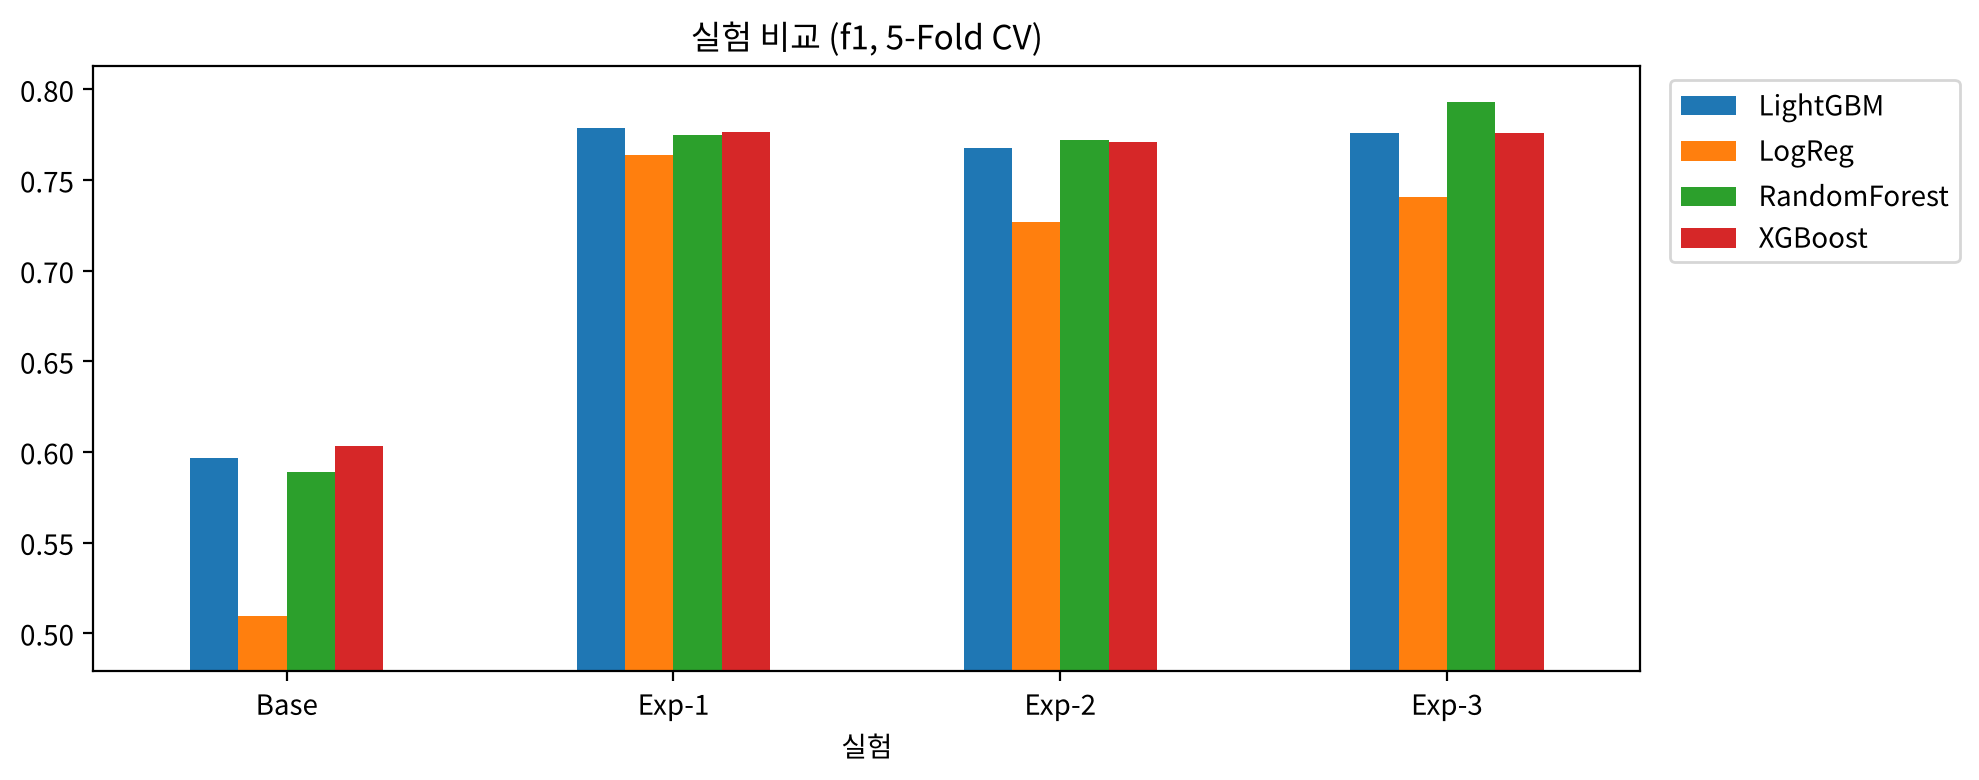

모델,LightGBM,LogReg,RandomForest,XGBoost
실험,,,,
Base,0.7586,0.7061,0.7614,0.7644
Exp-1,0.8823,0.8705,0.8818,0.8813
Exp-2,0.8768,0.8556,0.8825,0.8711
Exp-3,0.8685,0.8618,0.8797,0.8717


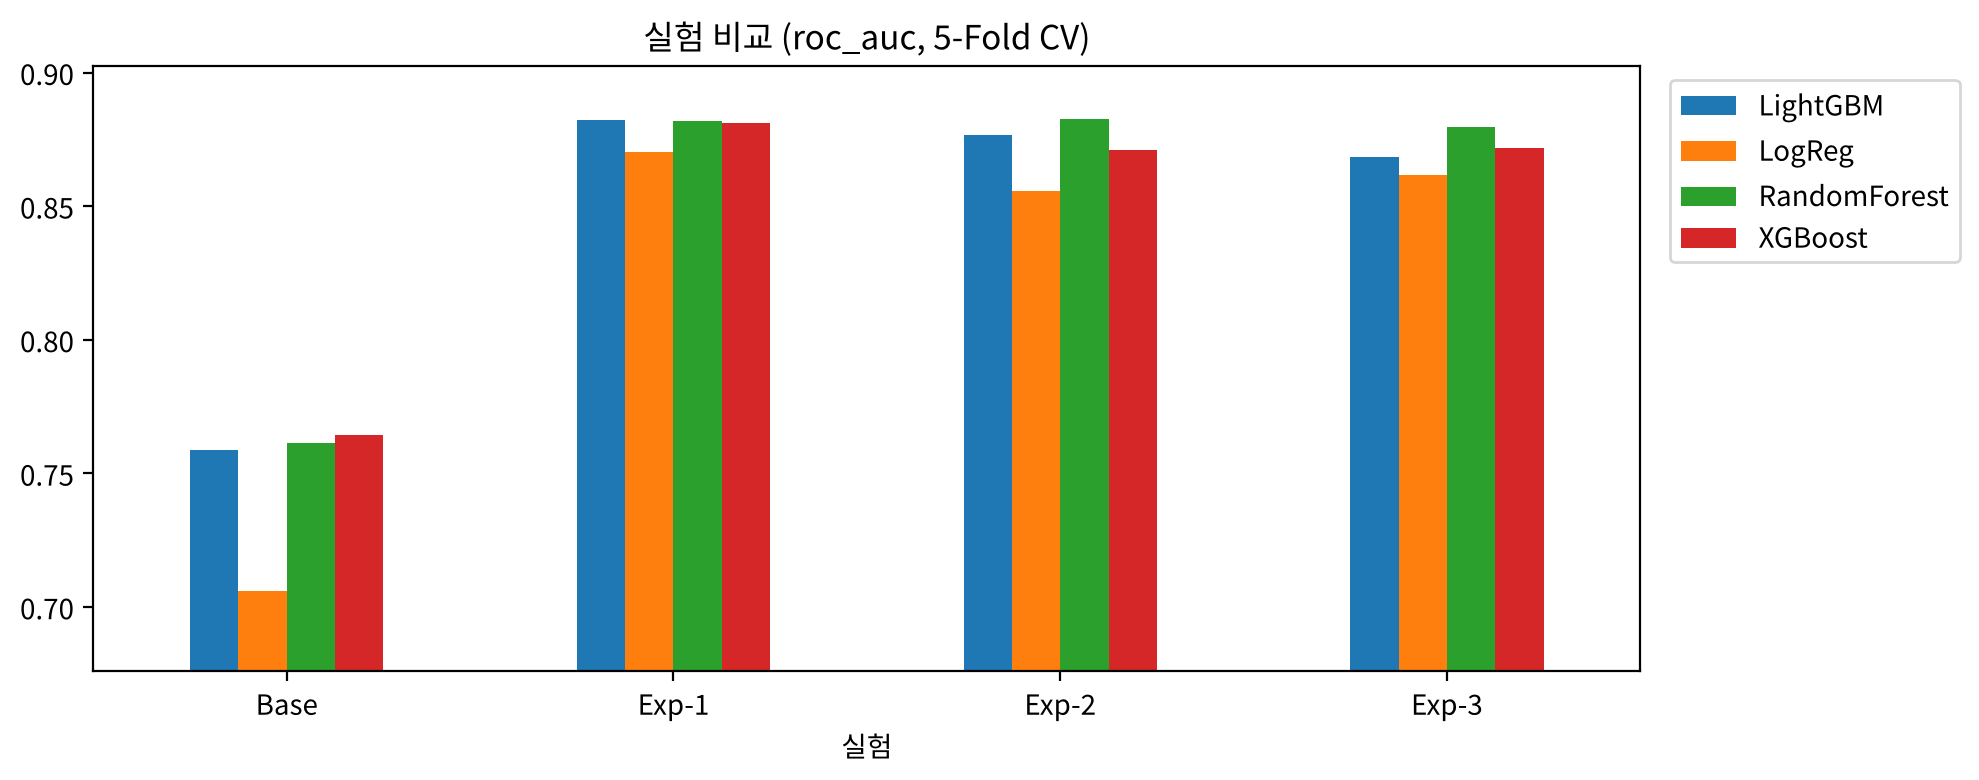

In [19]:
BASE_COLS = ["Pclass", "SibSp", "Parch", "Fare"]

def build_base(model):
    return Pipeline([("prep", ColumnTransformer([("raw", "passthrough", BASE_COLS)])), ("model", model)])

MAIN_EXPS = {
    "Exp-1": dict(impute="mean", encode="onehot", scale="Standard", select_top=None),
    "Exp-2": dict(impute="median", encode="label", scale="MinMax", select_top=10),
    "Exp-3": dict(impute="most_frequent", encode="onehot", scale="Robust", select_top=10),
}

rows = []
for mname, model in make_models().items():
    rows.append({"실험": "Base", "모델": mname, **evaluate(build_base(model), X, y)})
res_main = pd.concat([pd.DataFrame(rows), run_experiments(MAIN_EXPS, X, y)], ignore_index=True)

for metric in ["accuracy", "f1", "roc_auc"]:
    show(res_main, metric=metric, title="실험 비교")

### 5-1. 전체 성능 비교표 (보고서에 넣을 표)

In [20]:
table = res_main.set_index(["실험", "모델"])[SCORING + ["train_acc", "gap(train-val)"]]
table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Train Acc", "Gap"]
display(table.style.format("{:.4f}").background_gradient(subset=["Accuracy", "F1", "ROC-AUC"], cmap="Greens"))
table.round(4).to_csv("results_main.csv", encoding="utf-8-sig")   # 보고서용 저장

### 5-2. 최종 모델 — 홀드아웃(20%) 평가
CV 정확도가 가장 높은 (실험, 모델) 조합을 골라 처음 보는 데이터로 확인

최고 조합: Exp-3 / RandomForest  (CV Accuracy 0.8474)


Accuracy     0.7989
Precision    0.7538
Recall       0.7101
F1           0.7313
ROC-AUC      0.8457
dtype: float64
              precision    recall  f1-score   support

          사망       0.82      0.85      0.84       110
          생존       0.75      0.71      0.73        69

    accuracy                           0.80       179
   macro avg       0.79      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



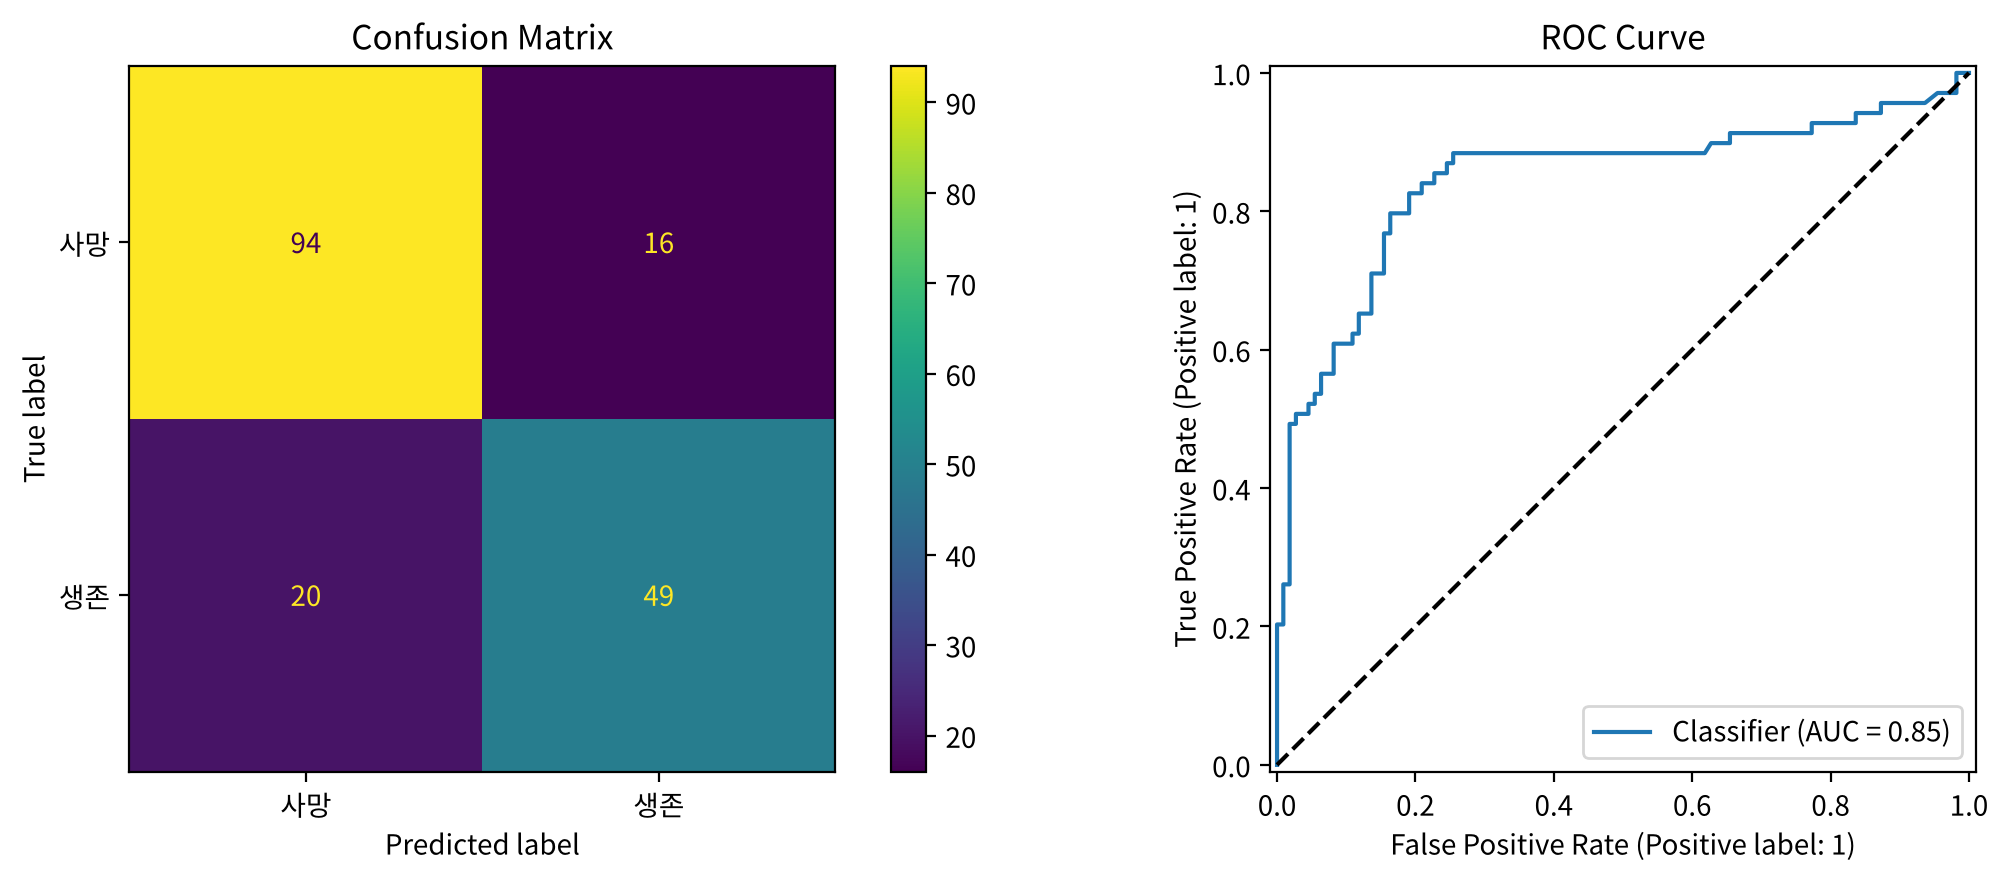

In [21]:
best = res_main[res_main["실험"] != "Base"].sort_values("accuracy", ascending=False).iloc[0]
print(f"최고 조합: {best['실험']} / {best['모델']}  (CV Accuracy {best['accuracy']:.4f})")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
final_pipe = build_pipeline(make_models()[best["모델"]], **MAIN_EXPS[best["실험"]]).fit(X_tr, y_tr)
pred = final_pipe.predict(X_te); proba = final_pipe.predict_proba(X_te)[:, 1]

print(pd.Series({"Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
                 "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred),
                 "ROC-AUC": roc_auc_score(y_te, proba)}).round(4))
print(classification_report(y_te, pred, target_names=["사망", "생존"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["사망", "생존"], ax=axes[0])
RocCurveDisplay.from_predictions(y_te, proba, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "k--")
axes[0].set_title("Confusion Matrix"); axes[1].set_title("ROC Curve")
plt.tight_layout(); plt.show()

## [가산점] GridSearchCV 하이퍼파라미터 튜닝
Exp-1 설정 + XGBoost로 튜닝 (Pipeline 단계 이름 `model__` 접두어로 파라미터 지정)

In [22]:
gs_pipe = build_pipeline(XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1), **MAIN_EXPS["Exp-1"])
param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [3, 4, 6],
    "model__learning_rate": [0.03, 0.1],
    "model__subsample": [0.8, 1.0],
}
gs = GridSearchCV(gs_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X, y)
print("Best params:", gs.best_params_)
print(f"Best CV Accuracy: {gs.best_score_:.4f}")
base_xgb = res_main.query("실험 == 'Exp-1' and 모델 == 'XGBoost'")["accuracy"].iloc[0]
print(f"튜닝 전 (Exp-1, XGBoost): {base_xgb:.4f} → 튜닝 후: {gs.best_score_:.4f}")

Best params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100, 'model__subsample': 0.8}
Best CV Accuracy: 0.8462
튜닝 전 (Exp-1, XGBoost): 0.8350 → 튜닝 후: 0.8462


## [가산점] SHAP 기반 설명 가능성 분석
튜닝된 XGBoost가 각 변수를 어떻게 사용하는지 확인

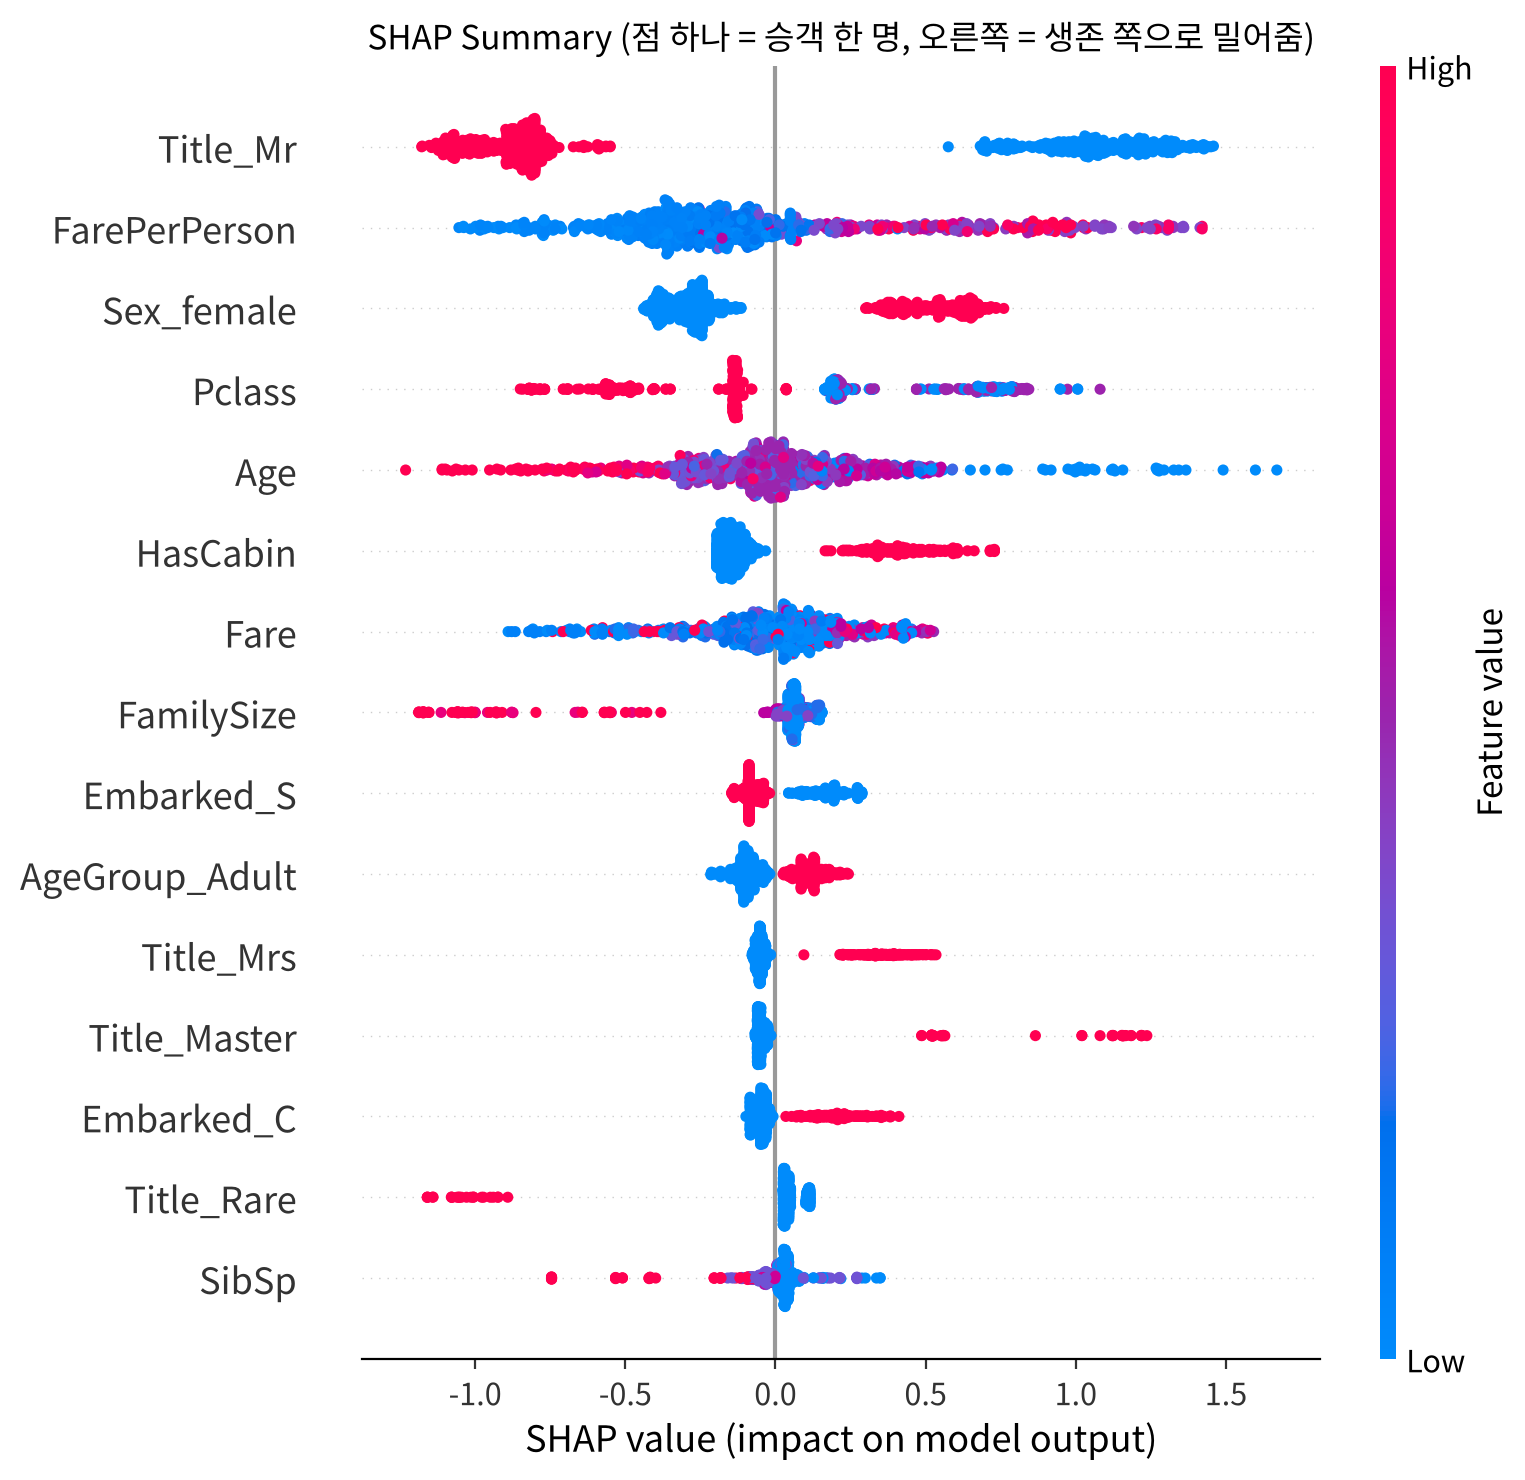

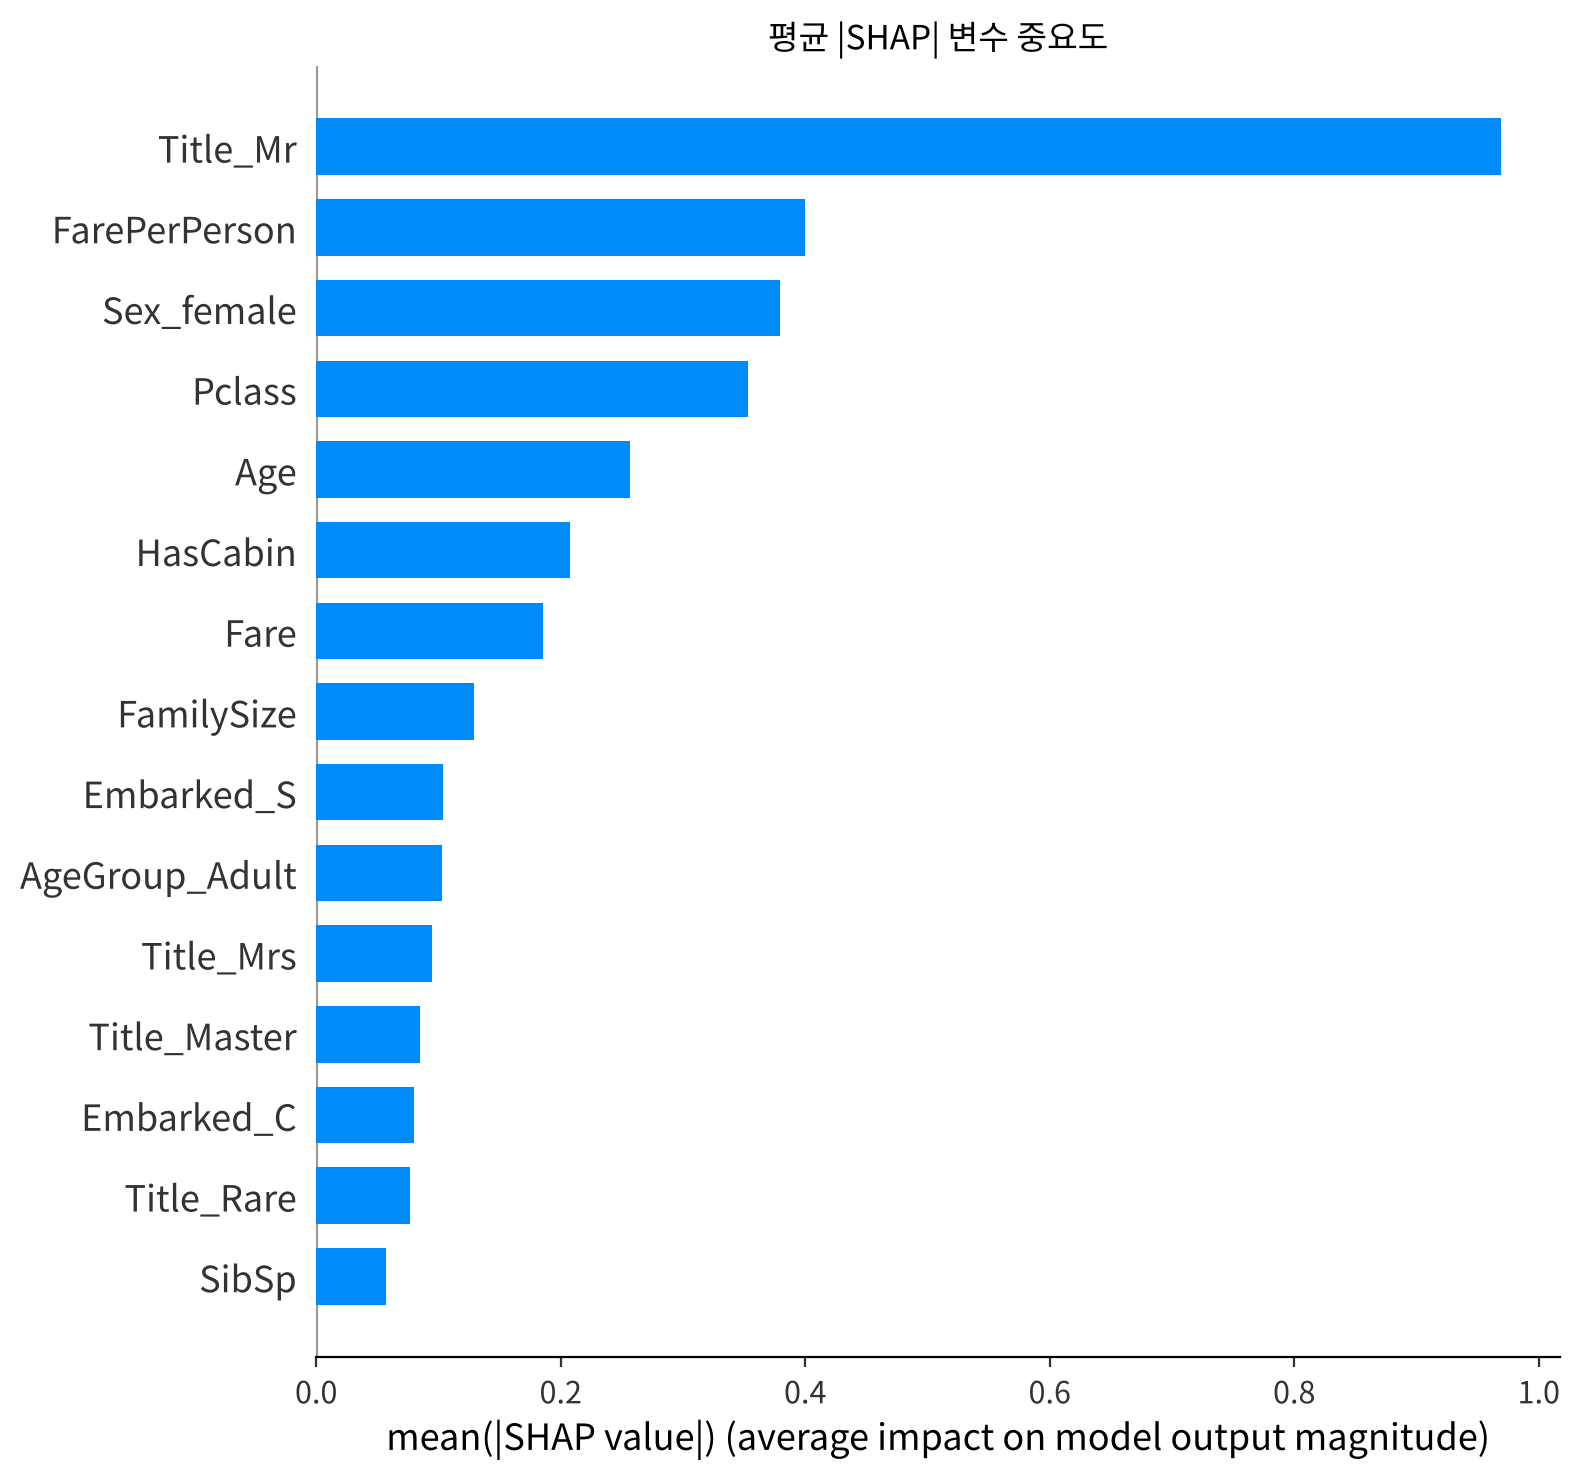

Title_Mr          0.9689
FarePerPerson     0.3999
Sex_female        0.3796
Pclass            0.3533
Age               0.2564
HasCabin          0.2076
Fare              0.1855
FamilySize        0.1288
Embarked_S        0.1039
AgeGroup_Adult    0.1027
dtype: float32


In [23]:
import shap
import xgboost as xgb

best_xgb = gs.best_estimator_
X_trans = best_xgb.named_steps["prep"].transform(X)
names = best_xgb.named_steps["prep"].get_feature_names_out()
X_trans = pd.DataFrame(X_trans, columns=[n.split("__", 1)[1] for n in names])

# XGBoost 내장 SHAP 계산 (shap 라이브러리와 xgboost 버전 충돌 회피)
booster = best_xgb.named_steps["model"].get_booster()
contribs = booster.predict(xgb.DMatrix(X_trans.values), pred_contribs=True)
shap_values = contribs[:, :-1]   # 마지막 열은 기준값(bias)이라 제외

shap.summary_plot(shap_values, X_trans, max_display=15, show=False)
plt.title("SHAP Summary (점 하나 = 승객 한 명, 오른쪽 = 생존 쪽으로 밀어줌)"); plt.tight_layout(); plt.show()
shap.summary_plot(shap_values, X_trans, plot_type="bar", max_display=15, show=False)
plt.title("평균 |SHAP| 변수 중요도"); plt.tight_layout(); plt.show()
print((pd.Series(np.abs(shap_values).mean(0), index=X_trans.columns).sort_values(ascending=False).head(10)).round(4))

## [가산점] Feature Importance 시각화 고도화
모델 4종의 변수 중요도를 정규화해 한 화면에서 비교 (LogReg는 계수 절댓값)

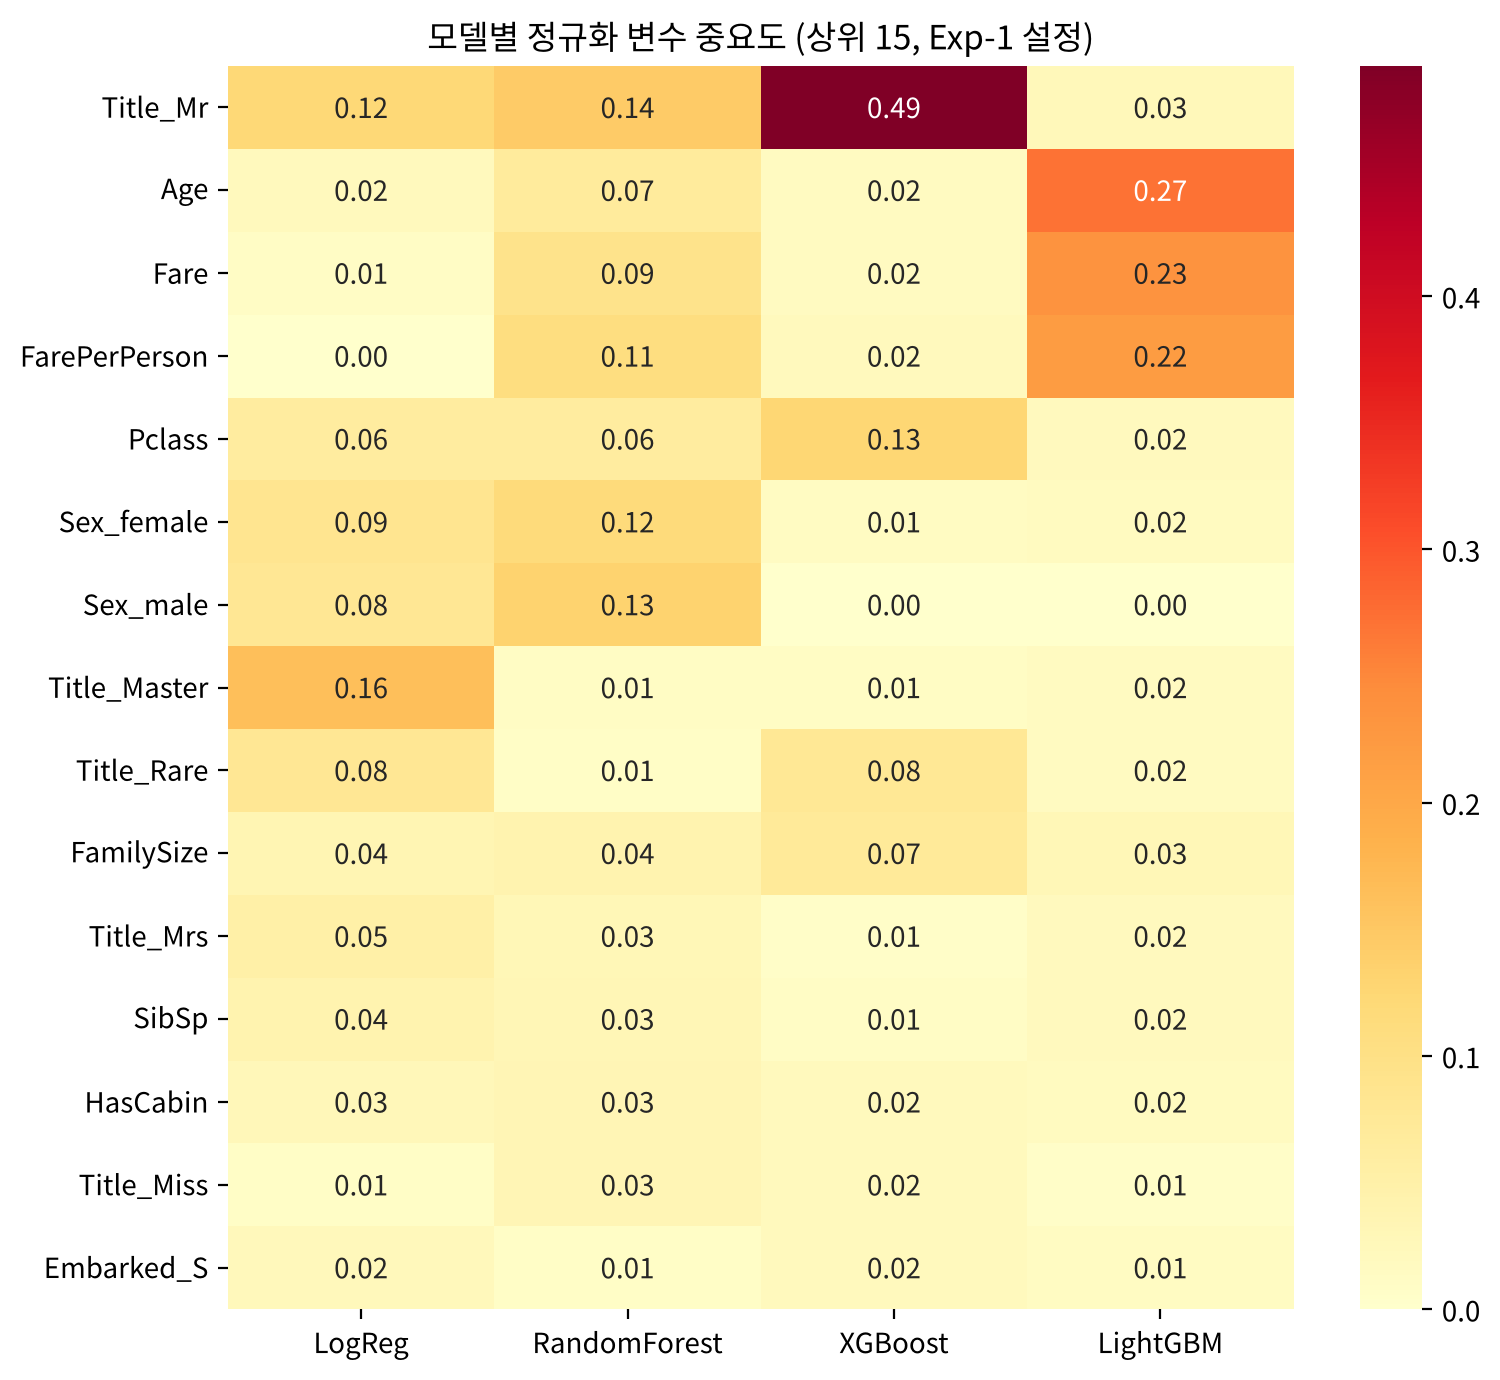

In [24]:
imp_table = {}
for mname, model in make_models().items():
    p = build_pipeline(model, **MAIN_EXPS["Exp-1"]).fit(X, y)
    m = p.named_steps["model"]
    raw = np.abs(m.coef_[0]) if mname == "LogReg" else m.feature_importances_
    imp_table[mname] = pd.Series(raw / raw.sum(), index=[n.split("__", 1)[1] for n in p.named_steps["prep"].get_feature_names_out()])
imp_table = pd.DataFrame(imp_table)
top = imp_table.mean(axis=1).sort_values(ascending=False).head(15).index

plt.figure(figsize=(8, 7))
sns.heatmap(imp_table.loc[top], annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("모델별 정규화 변수 중요도 (상위 15, Exp-1 설정)"); plt.tight_layout(); plt.show()

## 최종 결론

**1. 어떤 전처리 전략이 가장 효과적이었는가?**
- 가장 큰 효과는 **전처리 자체의 유무**였다. 결측치 처리·인코딩·파생 변수를 적용하자 Base 대비 Accuracy가 모든 모델에서 10~14%p 올랐다 (예: LogReg 0.682 → 0.824, RandomForest 0.723 → 0.847).
- 이는 Base가 쓰지 못한 `Sex`, `Age`, `Title` 같은 정보를 인코딩·결측치 처리로 모델에 넣을 수 있게 됐기 때문이다.
- 결측치 처리 방식(Mean / Median / Most Frequent) 간 차이는 0.5%p 이내로 작았다. Drop NA는 표본이 891 → 712로 줄어 모든 모델에서 가장 낮았다 (0.817~0.822). 데이터가 적을 때는 행을 버리는 것보다 대체가 낫다.
- 최종 최고 조합은 **Exp-3 (Most Frequent + One-Hot + Robust + RF 상위 10개) + RandomForest**, CV Accuracy 0.847 / F1 0.793이다.

**2. One-Hot Encoding이 항상 좋은가?**
- **아니다.** 3-2 결과 LogReg는 One-Hot 0.824 vs Label 0.801로 One-Hot이 2.2%p 높았지만, 트리 모델은 차이가 거의 없었고 LightGBM은 오히려 Label이 조금 높았다 (0.836 vs 0.831).
- 선형 모델은 Label 인코딩의 정수(0, 1, 2…)를 크기로 해석해 존재하지 않는 순서를 학습한다. 트리 모델은 값을 분할 기준으로만 쓰므로 영향이 적다. 같은 이유로 Label 인코딩을 쓴 Exp-2에서 LogReg만 크게 떨어졌다 (0.800).
- 따라서 **선형 모델에는 One-Hot, 트리 모델에는 둘 다 가능(변수 수가 적은 Label이 효율적)** 으로 모델에 따라 골라야 한다.

**3. Feature Selection이 과적합 감소에 기여했는가?**
- **부스팅 모델에서는 기여했다.** RF 중요도 상위 10개만 남기자 Train-Val Gap이 XGBoost 0.088 → 0.072, LightGBM 0.107 → 0.094로 줄었고, 검증 정확도는 오히려 올랐다 (XGBoost 0.833 → 0.841, RandomForest 0.837 → 0.845).
- 반면 LogReg는 원래 Gap이 0.01 수준으로 과적합이 거의 없어, 변수를 줄이자 정보 손실로 성능만 떨어졌다 (0.824 → 0.807). 상위 5개까지 줄이면 대부분 모델에서 성능이 하락했다.
- 즉, 변수 선택은 **복잡한 모델의 과적합을 줄이는 데 유효하지만 적정 개수(여기서는 약 10개)를 넘어 줄이면 손해**다.

**4. 스케일링이 모델별로 어떤 영향을 미쳤는가?**
- 트리 계열(RandomForest, XGBoost)은 스케일러를 바꿔도 결과가 **완전히 같았다.** 트리는 값의 대소 순서로만 분할하기 때문이다.
- LogReg는 MinMax가 0.832로 가장 높았고 None / Standard / Robust는 0.824로 같았다. 규제(L2)가 걸린 선형 모델은 변수 범위에 따라 계수 크기가 달라져 영향을 받는다.
- Fare 이상치(IQR 기준 13%)가 많아 Robust의 효과를 기대했으나 차이는 작았다. 원-핫 변수가 많아 수치형 스케일의 비중이 크지 않았기 때문으로 보인다.

**5. Feature Engineering이 실제 성능 향상에 얼마나 기여했는가?**
- 전체 파이프라인 기준: Base 최고 0.734 (XGBoost) → 최종 0.847 (Exp-3 RandomForest), **+11.3%p**. ROC-AUC도 0.76 → 0.88로 올랐다.
- 파생 변수만 따로 보면(3-4) LogReg는 0.794 → 0.824로 **+3%p** 향상됐지만, 트리 모델은 거의 변화가 없었다. 트리는 SibSp·Parch 조합 같은 상호작용을 스스로 학습하므로, 사람이 만든 파생 변수의 이득은 선형 모델에서 더 크다.
- 그래도 SHAP 분석에서 가장 중요한 변수는 파생 변수 **Title_Mr**이었고, **FarePerPerson**이 2위였다. 파생 변수가 모델의 판단 근거로 실제로 쓰이고 있다는 뜻이다.
- GridSearchCV 튜닝으로 XGBoost를 0.835 → 0.846으로 추가 개선했다. 홀드아웃(20%) 평가에서는 Accuracy 0.799, ROC-AUC 0.846으로 CV보다 약간 낮아, 교차검증 점수가 다소 낙관적일 수 있음을 확인했다.

**한계 및 개선 방향**
- 실험 간 차이가 1%p 안팎인 경우가 많아, 반복 교차검증(Repeated CV)으로 분산을 줄여 비교할 필요가 있다.
- AutoML(예: FLAML, AutoGluon)과의 비교, test.csv 예측을 Kaggle에 제출해 외부 데이터로 검증하는 것을 추가할 수 있다.